<a href="https://colab.research.google.com/github/11465005-tech/ChineseEmoBank_ValenceArousal/blob/main/chinese_pipelined_v8_UniCtx_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 中文版 Pipelined Neural Networks v8-UniCtx — 統一語境的遞迴 Pipeline
## v8-UniCtx 相對 v7-2 / v7-3c 的改動（依最近一次教授會議結論）
1. **句子層簡化**：不再區分 `hit=0` / `hit=1` 兩種 span 的處理路徑。所有 span 一律走
   `BERT(span [SEP] 整句)` → 同一個 `SpanContextAdapter` → 同一個遞迴 `NNsent.step()`，
   VA 都參考整句語境；`hit` 只是一個輸入特徵。
2. **看過／沒看過的詞走同一條路**：對任何詞都用同一套「鄰近度傳播 + gate」
   （BERT 向量到 `cvaw_train` 的 top-k 近鄰 → 鄰居 VA 與相似度 conf），
   並可依 conf 把 CVAW 以外、但像情緒詞的字收進來當 span（`UNICTX_OOV_SPANS`）。
3. **NNword 對沒看過的詞的量化診斷**（14.2b）：NNword vs 鄰居傳播 vs 混合，以及 conf 能否預測誤差。
4. 修正 v7 的一個 bug：「整句向量」原本用 `max_length=16`，其實只看到句子前約 14 個字；v8 改成 128。
5. 固定隨機種子（v7 沒有），消融開關：`UNICTX_USE_KNN` / `UNICTX_OOV_SPANS`。

Stage 1（NNword）與 Stage 2（NNmod）以及第 0–13 節與 v7-2 完全相同。

## 架構設計
```
Stage 1: BERT(word) -> NNword -> Int(w)
Stage 2: BERT(core) -> NNword(frozen) -> Int(w)
         BERT(modifier [SEP] core/phrase) -> NNmod(frozen) -> Int(mod phrase)
Stage 3: 每個 span: BERT(span [SEP] 整句) + 鄰近度 gate -> SpanContextAdapter -> 遞迴 NNsent.step
```

## 0. 安裝套件

In [ ]:
# 已安裝好的 Colab 環境可略過；第一次跑或套件版本不對時再打開這行
# !pip install transformers torch pandas numpy scikit-learn scipy matplotlib -q

## 1. 設定執行環境（Colab 版：掛載 Google Drive、偵測 GPU）

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import kendalltau, spearmanr, pearsonr
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import TensorDataset, DataLoader

from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'使用裝置: {device}')

try:
    import subprocess, glob
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'fonts-noto-cjk'],
                    check=True, capture_output=True, text=True)
    subprocess.run(['fc-cache', '-f'], capture_output=True)

    import matplotlib.font_manager as fm
    # apt 裝好字型檔之後，matplotlib 這個 process 裡的字型快取不會自動更新，
    # 一定要用 addfont() 手動註冊剛裝好的字型檔，否則畫圖時還是找不到、
    # 悄悄退回沒有中文字的預設字型（之前中文變方塊的原因）。
    for fp in glob.glob('/usr/share/fonts/**/*CJK*', recursive=True):
        try:
            fm.fontManager.addfont(fp)
        except Exception:
            pass

    cjk_candidates = ['Noto Sans CJK TC', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
    available = {f.name for f in fm.fontManager.ttflist}
    cjk_font = next((c for c in cjk_candidates if c in available), None)
    if cjk_font is None:
        cjk_font = next((f.name for f in fm.fontManager.ttflist if 'CJK' in f.name), None)

    if cjk_font:
        plt.rcParams['font.sans-serif'] = [cjk_font]
        plt.rcParams['font.family'] = 'sans-serif'
        plt.rcParams['axes.unicode_minus'] = False
        print(f'[字型] 已安裝並套用中文字型: {cjk_font}')
    else:
        print('[字型] \u26a0 套件裝好了，但沒偵測到 CJK 字型名稱，圖中中文可能還是方塊——'
              '「執行階段 > 重新啟動工作階段」後再重跑全部通常能解決。')
except Exception as e:
    print(f'[字型] \u26a0 安裝中文字型失敗：{e}')
    print('  可以在上面另開一格手動執行：!apt-get install -y fonts-noto-cjk && fc-cache -f')
    print('  裝完後「執行階段 > 重新啟動工作階段」，再重跑全部 cell')

Mounted at /content/drive
使用裝置: cpu
[字型] 已安裝並套用中文字型: Noto Sans CJK JP


## 路徑設定（Colab 版：Google Drive 路徑，需要的話自行修改）

In [ ]:
BASE     = '/content/drive/MyDrive/研究/dimABSA/DataSets/ChineseEmoBank'
SAVE_DIR = '/content/drive/MyDrive/研究/dimABSA/models'
BERT_NAME = 'hfl/chinese-bert-wwm-ext'

import os; os.makedirs(SAVE_DIR, exist_ok=True)

## 資料載入（Colab 版：從 Google Drive 讀取 CSV）

In [ ]:
def read_csv_robust(path, sep='\t', _retried=False):
    # Google Drive 在 Colab 是用 FUSE 掛載的，長時間跑、或連續讀好幾個檔案時
    # 偶爾會斷線（OSError: [Errno 107] Transport endpoint is not connected）——
    # 這是 Drive 掛載點本身失聯，不是檔案壞掉，重新掛載一次通常就會好。
    for enc in ['utf-8', 'utf-8-sig', 'big5', 'gb18030', 'cp950']:
        try:
            df = pd.read_csv(path, sep=sep, encoding=enc)
            print(f'  -> {path.split("/")[-1]} 使用編碼: {enc}')
            return df
        except (UnicodeDecodeError, UnicodeError):
            continue
        except OSError as e:
            if _retried:
                raise
            print(f'  \u26a0 讀取 {path.split("/")[-1]} 時 Google Drive 連線中斷（{e}），'
                  f'重新掛載 Drive 後重試一次...')
            from google.colab import drive
            drive.mount('/content/drive', force_remount=True)
            return read_csv_robust(path, sep=sep, _retried=True)
    return pd.read_csv(path, sep=sep, encoding='utf-8', encoding_errors='replace')

cvaw = read_csv_robust(f'{BASE}/CVAW_SD/CVAW_all_SD.csv')
cvap = read_csv_robust(f'{BASE}/CVAP_SD/CVAP_all_SD.csv')
cvas = read_csv_robust(f'{BASE}/CVAS_SD/CVAS_all.csv')
print(f'CVAW: {len(cvaw)}  CVAP: {len(cvap)}  CVAS: {len(cvas)}')

  -> CVAW_all_SD.csv 使用編碼: utf-8
  -> CVAP_all_SD.csv 使用編碼: utf-8
  -> CVAS_all.csv 使用編碼: utf-8
CVAW: 5512  CVAP: 2250  CVAS: 2583


## [新增] CVAW 詞典 Valence-Arousal 散佈圖（仿論文 Fig. 3 樣式）

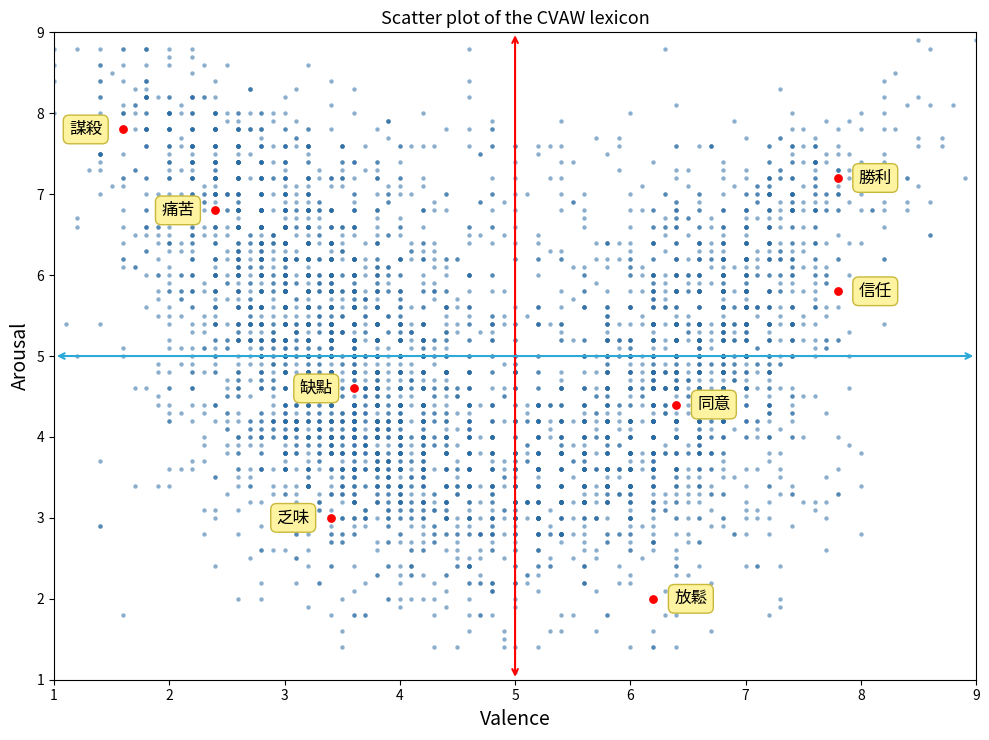

已標註的詞: {'痛苦', '謀殺', '信任', '乏味', '同意', '放鬆', '缺點', '勝利'}


In [ ]:
LABEL_WORDS = [
    ('謀殺', (-15, 0),  (1.6, 8.0)),   # 左上：高激發、負向
    ('痛苦', (-15, 0),  (2.0, 6.8)),
    ('勝利', (15, 0),   (7.8, 7.0)),   # 右上：高激發、正向
    ('信任', (15, 0),   (7.8, 5.7)),
    ('缺點', (-15, 0),  (3.6, 4.5)),   # 中間偏負
    ('同意', (15, 0),   (6.4, 4.3)),   # 中間偏正
    ('乏味', (-15, 0),  (2.5, 3.0)),   # 左下：低激發、負向
    ('放鬆', (15, 0),   (6.3, 2.0)),   # 右下：低激發、正向
]


def _nearest_word(df, target_v, target_a, exclude=set()):
    d = (df['Valence_Mean'] - target_v) ** 2 + (df['Arousal_Mean'] - target_a) ** 2
    d[df['Word'].isin(exclude)] = np.inf
    idx = d.idxmin()
    return df.loc[idx, 'Word'], df.loc[idx, 'Valence_Mean'], df.loc[idx, 'Arousal_Mean']


def plot_cvaw_scatter(df):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(df['Valence_Mean'], df['Arousal_Mean'],
               s=10, color='#2b6ca3', alpha=0.55, linewidths=0, zorder=2)
    ax.annotate('', xy=(5, 9), xytext=(5, 1),
                arrowprops=dict(arrowstyle='<->', color='red', lw=1.5), zorder=3)
    ax.annotate('', xy=(9, 5), xytext=(1, 5),
                arrowprops=dict(arrowstyle='<->', color='#2ca9d6', lw=1.5), zorder=3)

    used_words = set()
    for word, offset, fallback_xy in LABEL_WORDS:
        row = df[df['Word'] == word]
        if len(row):
            v, a = row.iloc[0]['Valence_Mean'], row.iloc[0]['Arousal_Mean']
            label = word
        else:
            label, v, a = _nearest_word(df, *fallback_xy, exclude=used_words)
        used_words.add(label)
        ax.scatter([v], [a], s=28, color='red', zorder=4)
        ax.annotate(label, xy=(v, a), xytext=offset, textcoords='offset points',
                    fontsize=12, va='center',
                    ha='right' if offset[0] < 0 else 'left',
                    bbox=dict(boxstyle='round,pad=0.35', facecolor='#fdf3a0',
                              edgecolor='#c9b93a', linewidth=1),
                    zorder=5)

    ax.set_xlim(1, 9); ax.set_ylim(1, 9)
    ax.set_xlabel('Valence', fontsize=14)
    ax.set_ylabel('Arousal', fontsize=14)
    ax.set_title('Scatter plot of the CVAW lexicon', fontsize=13)
    plt.tight_layout()
    plt.savefig('cvaw_scatter.png', dpi=200)
    plt.show()
    print('已標註的詞:', used_words)


plot_cvaw_scatter(cvaw)

## [新增] 通用版 VA 散佈圖工具（給 NNword / NNmod / NNsent 預測結果用）

In [ ]:
VA_SCATTER_ANCHORS = [
    ((-15, 0), (1.6, 8.0)),
    ((-15, 0), (2.0, 6.8)),
    ((15, 0),  (7.8, 7.0)),
    ((15, 0),  (7.8, 5.7)),
    ((-15, 0), (3.6, 4.5)),
    ((15, 0),  (6.4, 4.3)),
    ((-15, 0), (2.5, 3.0)),
    ((15, 0),  (6.3, 2.0)),
]


def _nearest_item(vs, as_, texts, target_v, target_a, exclude):
    d = (vs - target_v) ** 2 + (as_ - target_a) ** 2
    d = d.copy()
    for i in exclude:
        d[i] = np.inf
    idx = int(np.argmin(d))
    return idx, vs[idx], as_[idx], texts[idx]


def plot_va_scatter(values_v, values_a, texts, title, savepath=None, max_len=10):
    """
    values_v / values_a：模型輸出的正規化 [0,1] VA 陣列，自動還原成 1-9 分數畫圖。
    texts：對應每個點的原文字（詞／短語／句子），自動挑離八個象限錨點最近的
           實際樣本標註，不用手動指定詞表。
    """
    vs = np.asarray(values_v, dtype=np.float64) * 8 + 1
    as_ = np.asarray(values_a, dtype=np.float64) * 8 + 1
    texts = list(texts)

    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(vs, as_, s=10, color='#2b6ca3', alpha=0.45, linewidths=0, zorder=2)
    ax.annotate('', xy=(5, 9), xytext=(5, 1),
                arrowprops=dict(arrowstyle='<->', color='red', lw=1.5), zorder=3)
    ax.annotate('', xy=(9, 5), xytext=(1, 5),
                arrowprops=dict(arrowstyle='<->', color='#2ca9d6', lw=1.5), zorder=3)

    used = set()
    for offset, (tv, ta) in VA_SCATTER_ANCHORS:
        idx, v, a, txt = _nearest_item(vs, as_, texts, tv, ta, used)
        used.add(idx)
        label = txt if len(txt) <= max_len else txt[:max_len] + '…'
        ax.scatter([v], [a], s=28, color='red', zorder=4)
        ax.annotate(label, xy=(v, a), xytext=offset, textcoords='offset points',
                    fontsize=11, va='center',
                    ha='right' if offset[0] < 0 else 'left',
                    bbox=dict(boxstyle='round,pad=0.35', facecolor='#fdf3a0',
                              edgecolor='#c9b93a', linewidth=1),
                    zorder=5)

    ax.set_xlim(1, 9); ax.set_ylim(1, 9)
    ax.set_xlabel('Valence', fontsize=14)
    ax.set_ylabel('Arousal', fontsize=14)
    ax.set_title(title, fontsize=13)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
    plt.show()


print('plot_va_scatter 定義完成（NNword / NNmod / NNsent 共用）')

plot_va_scatter 定義完成（NNword / NNmod / NNsent 共用）


## 2. 資料前處理
v7-2 進一步加入否定詞範圍規則（例如「不是很」「並不太」），
提升複合修飾詞切割的穩定性，減少誤切。

In [ ]:
def normalize_va(df, val_col='Valence_Mean', aro_col='Arousal_Mean'):
    df = df.copy()
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce')
    df[aro_col] = pd.to_numeric(df[aro_col], errors='coerce')
    before = len(df)
    df = df.dropna(subset=[val_col, aro_col]).reset_index(drop=True)
    if before - len(df) > 0:
        print(f'  ⚠ 清除 {before-len(df)} 筆髒資料')
    df['valence'] = (df[val_col] - 1) / 8.0
    df['arousal'] = (df[aro_col] - 1) / 8.0
    return df
cvaw = normalize_va(cvaw)
cvap = normalize_va(cvap)
cvas = normalize_va(cvas)
# CVAP 短語切割：由右向左找核心詞 + 否定詞範圍規則
cvaw_word_set = set(cvaw['Word'].astype(str).tolist())
max_core_len = max(len(w) for w in cvaw_word_set)
# 否定詞與程度詞（長詞優先匹配）
NEGATION_CUES = {
    '不是很', '並不太', '並不是', '不怎麼', '不太', '不是', '並不', '沒有', '沒', '不', '無', '未', '別', '勿'
}
DEGREE_CUES = {
    '超級', '極為', '非常', '相當', '十分', '更加', '格外', '特別', '有點', '稍微', '很', '太', '更', '極', '超'
}
# 常見多詞修飾鏈，優先整體匹配
COMPOSITE_MODIFIERS = {
    '不是很', '並不太', '並不是很', '沒有很', '不怎麼', '不太'
}
MODIFIER_LEXICON = sorted(
    COMPOSITE_MODIFIERS | NEGATION_CUES | DEGREE_CUES,
    key=len,
    reverse=True
)
def normalize_text(s):
    s = str(s).strip()
    for ch in '，。！？、,.!?;；：「」『』（）() ':
        s = s.replace(ch, '')
    return s
def split_modifier_chain(modifier_text):
    """
    規則切分：
    1) 優先匹配複合否定程度詞（如 不是很/並不太）
    2) 次優先匹配一般否定或程度詞
    3) 未知片段退回單字，避免直接丟失資訊
    """
    txt = normalize_text(modifier_text)
    if not txt:
        return []
    mods = []
    i = 0
    while i < len(txt):
        matched = None
        for tok in MODIFIER_LEXICON:
            if txt.startswith(tok, i):
                matched = tok
                break
        if matched is None:
            matched = txt[i:i+1]
        mods.append(matched)
        i += len(matched)
    # 後處理：若出現「不是 + 很」「並不 + 太」再合併回範圍詞
    merged = []
    j = 0
    while j < len(mods):
        if j + 1 < len(mods):
            pair = mods[j] + mods[j + 1]
            if pair in COMPOSITE_MODIFIERS:
                merged.append(pair)
                j += 2
                continue
        merged.append(mods[j])
        j += 1
    return merged
def split_phrase(phrase, cvaw_words):
    phrase = normalize_text(phrase)
    candidates = []
    upper = min(max_core_len, len(phrase) - 1)
    for core_len in range(upper, 0, -1):
        core = phrase[-core_len:]
        modifier = phrase[:-core_len]
        if core in cvaw_words and len(modifier) > 0:
            mod_tokens = split_modifier_chain(modifier)
            neg_hits = sum(t in NEGATION_CUES for t in mod_tokens)
            deg_hits = sum(t in DEGREE_CUES for t in mod_tokens)
            # 先偏好含關鍵修飾詞，再偏好較長核心詞
            score = (neg_hits + deg_hits, neg_hits, core_len)
            candidates.append((score, modifier, core, mod_tokens))
    if candidates:
        _, modifier, core, mod_tokens = max(candidates, key=lambda x: x[0])
        return modifier, core, mod_tokens
    return None, None, []
mods, cores, mod_chains = [], [], []
for phrase in cvap['Phrase']:
    m, c, chain = split_phrase(phrase, cvaw_word_set)
    mods.append(m)
    cores.append(c)
    mod_chains.append(chain)
cvap['modifier'] = mods
cvap['core_word'] = cores
cvap['modifier_chain'] = mod_chains
cvap_aligned = cvap.dropna(subset=['modifier', 'core_word']).copy()
print(f'CVAP 對齊: {len(cvap_aligned)} / {len(cvap)} 筆')
print('切割示例（前 5 筆）:')
print(cvap_aligned[['Phrase', 'modifier', 'core_word', 'modifier_chain']].head().to_string(index=False))
# 8:2 切分
cvaw_train, cvaw_test = train_test_split(cvaw,         test_size=0.2, random_state=42)
cvap_train, cvap_test = train_test_split(cvap_aligned, test_size=0.2, random_state=42)
print(f'CVAW 訓練:{len(cvaw_train)}  測試:{len(cvaw_test)}')
print(f'CVAP 訓練:{len(cvap_train)}  測試:{len(cvap_test)}')

CVAP 對齊: 2249 / 2250 筆
切割示例（前 5 筆）:
Phrase modifier core_word modifier_chain
   怪八卦        怪        八卦            [怪]
  更加小心       更加        小心           [更加]
  格外小心       格外        小心           [格外]
  特別小心       特別        小心           [特別]
  極為小心       極為        小心           [極為]
CVAW 訓練:4409  測試:1103
CVAP 訓練:1799  測試:450


In [ ]:
# 規則切割 sanity check（否定詞範圍）
probe_phrases = [
    '不是很開心',
    '並不太滿意',
    '不怎麼快樂',
    '沒有很失望',
    '非常開心',
]
print('=== Modifier Scope Sanity Check ===')
for p in probe_phrases:
    m, c, chain = split_phrase(p, cvaw_word_set)
    print(f'{p:8s} -> modifier={m}, core={c}, chain={chain}')

=== Modifier Scope Sanity Check ===
不是很開心    -> modifier=不是很, core=開心, chain=['不是很']
並不太滿意    -> modifier=並不太, core=滿意, chain=['並不太']
不怎麼快樂    -> modifier=不怎麼, core=快樂, chain=['不怎麼']
沒有很失望    -> modifier=沒有很, core=失望, chain=['沒有很']
非常開心     -> modifier=非常, core=開心, chain=['非常']


## 3. 載入中文 BERT
v7-2 除了單詞向量，也新增「修飾詞 + 被修飾詞」的 pair 向量：  
`BERT(modifier [SEP] target_text)`，讓 NNmod 具備語境感知能力。

In [ ]:
BERT_NAME = 'hfl/chinese-bert-wwm-ext'
print(f'載入 {BERT_NAME}（約需 1~2 分鐘）...')
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert_model = AutoModel.from_pretrained(BERT_NAME).to(device)
BERT_DIM = bert_model.config.hidden_size
print(f'✅ 載入完成 | hidden size: {BERT_DIM}')
@torch.no_grad()
def get_bert_vec(text):
    """
    單輸入 BERT [CLS]。
    用於核心詞的 base 情緒表示。
    """
    bert_model.eval()
    enc = tokenizer(
        text, return_tensors='pt',
        padding=True, truncation=True, max_length=16
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
@torch.no_grad()
def get_bert_pair_vec(modifier, target_text):
    """
    語境化修飾詞向量：BERT(modifier [SEP] target_text)
    讓 NNmod 感知修飾詞正在修飾哪個詞/片語。
    """
    bert_model.eval()
    enc = tokenizer(
        modifier,
        target_text,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=24
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
# 批次版本（訓練時效率更高）
@torch.no_grad()
def get_bert_vecs_batch(texts, batch_size=64):
    bert_model.eval()
    all_vecs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = tokenizer(
            batch, return_tensors='pt',
            padding=True, truncation=True, max_length=16
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
@torch.no_grad()
def get_bert_pair_vecs_batch(modifiers, targets, batch_size=64):
    bert_model.eval()
    all_vecs = []
    n = len(modifiers)
    for i in range(0, n, batch_size):
        b_mod = modifiers[i:i+batch_size]
        b_tgt = targets[i:i+batch_size]
        enc = tokenizer(
            b_mod,
            b_tgt,
            return_tensors='pt',
            padding=True,
            truncation=True,
            max_length=24
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
# 測試
v1 = get_bert_vec('開心')
v2 = get_bert_vec('難過')
pair_v = get_bert_pair_vec('非常', '開心')
sim_happy_sad = float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))
print(f'開心 vs 難過 cosine: {sim_happy_sad:.4f}')
print(f'BERT 向量維度: {v1.shape} | pair 向量維度: {pair_v.shape}')

載入 hfl/chinese-bert-wwm-ext（約需 1~2 分鐘）...


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/19.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/269k [00:00<?, ?B/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  412MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: hfl/chinese-bert-wwm-ext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ 載入完成 | hidden size: 768
開心 vs 難過 cosine: 0.8179
BERT 向量維度: (768,) | pair 向量維度: (768,)


## 4. 模型定義
### NNword head：BERT 向量 → VA 值
維持單詞基準情緒估計。
### NNmod：語境化修飾 + V/A 互動
輸入改為 `BERT(modifier [SEP] target_text)`，並加入 `v, a, v*a, v-a` 互動特徵，
讓 Valence/Arousal 的偏移可共享語意表示、降低獨立建模限制。

In [ ]:
class NNword(nn.Module):
    """
    v7-2 版 NNword：BERT [CLS] → Valence / Arousal
    輸入：BERT 768 維向量（單詞）
    輸出：val, aro ∈ [0,1]
    """
    def __init__(self, bert_dim=768):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(bert_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )
    def forward(self, bert_vec):
        out = torch.sigmoid(self.net(bert_vec))
        return out[:, 0:1], out[:, 1:2]
class NNmod(nn.Module):
    """
    v7-2 版 NNmod：語境化修飾 + V/A 互動建模
    輸入：
      1) Int_val(w), Int_aro(w)
      2) BERT(modifier [SEP] target_text) 的語境向量
    設計重點：
      - delta 由 shared hidden 同時決定 val/aro（共享表示，允許耦合）
      - 加入 [v, a, v*a, v-a] 互動特徵
      - 回傳 c_mod_v / c_mod_a，便於雙維度分析
      - 使用 LayerNorm 以支援遞迴鏈訓練時的 batch size=1
    """
    def __init__(self, bert_dim=768):
        super().__init__()
        feat_dim = bert_dim + 4
        self.fc1 = nn.Linear(feat_dim, 192)
        self.fc2 = nn.Linear(192, 64)
        self.fc3 = nn.Linear(64, 2)
        self.ln1 = nn.LayerNorm(192)
        self.ln2 = nn.LayerNorm(64)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    def forward(self, int_val, int_aro, bert_mod_ctx):
        va_feat = torch.cat([
            int_val,
            int_aro,
            int_val * int_aro,
            int_val - int_aro
        ], dim=1)
        x = torch.cat([bert_mod_ctx, va_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        delta_v = delta[:, 0:1]
        delta_a = delta[:, 1:2]
        out_v = torch.sigmoid(torch.logit(int_val.clamp(0.01, 0.99)) + delta_v * 3)
        out_a = torch.sigmoid(torch.logit(int_aro.clamp(0.01, 0.99)) + delta_a * 3)
        c_mod_v = delta_v + 0.5
        c_mod_a = delta_a + 0.5
        return out_v, out_a, c_mod_v, c_mod_a
print('NNword / NNmod（v7-2）定義完成')

NNword / NNmod（v7-2）定義完成


## 5. 預先計算所有 BERT 向量（含遞迴鏈）
除了 core word 向量，也快取遞迴鏈每一步需要的 pair context 向量：  
`modifier [SEP] current_phrase`，供 Stage 2 直接訓練多層遞迴鏈。

In [ ]:
print('預先計算 CVAW 訓練集詞向量...')
word_train_vecs = get_bert_vecs_batch(cvaw_train['Word'].tolist())
word_train_val  = cvaw_train['valence'].values.astype(np.float32)
word_train_aro  = cvaw_train['arousal'].values.astype(np.float32)
print('預先計算 CVAW 測試集詞向量...')
word_test_vecs  = get_bert_vecs_batch(cvaw_test['Word'].tolist())
word_test_val   = cvaw_test['valence'].values.astype(np.float32)
word_test_aro   = cvaw_test['arousal'].values.astype(np.float32)
print('建立遞迴鏈訓練樣本（含 context cache）...')
core_cache = {}
pair_cache = {}
def get_core_vec_cached(word):
    if word not in core_cache:
        core_cache[word] = get_bert_vec(word)
    return core_cache[word]
def get_pair_vec_cached(modifier, target):
    key = (modifier, target)
    if key not in pair_cache:
        pair_cache[key] = get_bert_pair_vec(modifier, target)
    return pair_cache[key]
def build_recursive_chain_samples(df):
    samples = []
    for _, row in df.iterrows():
        core = str(row['core_word'])
        chain = row['modifier_chain'] if isinstance(row['modifier_chain'], list) else []
        if len(chain) == 0:
            chain = [str(row['modifier'])]
        cur_phrase = core
        ctx_chain = []
        # 由最靠近核心詞者先作用，因此反向展開
        for mod in reversed(chain):
            mod = str(mod)
            ctx_chain.append(get_pair_vec_cached(mod, cur_phrase))
            cur_phrase = mod + cur_phrase
        samples.append({
            'core_word': core,
            'full_phrase': str(row['Phrase']),
            'mods_outer_to_inner': chain,
            'ctx_chain': ctx_chain,
            'core_vec': get_core_vec_cached(core),
            'valence': float(row['valence']),
            'arousal': float(row['arousal']),
        })
    return samples
train_chain_samples = build_recursive_chain_samples(cvap_train)
test_chain_samples  = build_recursive_chain_samples(cvap_test)
# 保留舊變數名稱方便後續 cell 相容
core_train_vecs = np.stack([s['core_vec'] for s in train_chain_samples]).astype(np.float32)
core_test_vecs  = np.stack([s['core_vec'] for s in test_chain_samples]).astype(np.float32)
phrase_train_val = np.array([s['valence'] for s in train_chain_samples], dtype=np.float32)
phrase_train_aro = np.array([s['arousal'] for s in train_chain_samples], dtype=np.float32)
phrase_test_val  = np.array([s['valence'] for s in test_chain_samples], dtype=np.float32)
phrase_test_aro  = np.array([s['arousal'] for s in test_chain_samples], dtype=np.float32)
# Stage 1 張量（維持不變）
wt_v = torch.tensor(word_train_vecs).to(device)
wt_y_v = torch.tensor(word_train_val).unsqueeze(1).to(device)
wt_y_a = torch.tensor(word_train_aro).unsqueeze(1).to(device)
chain_lens = np.array([len(s['ctx_chain']) for s in train_chain_samples])
print(f'詞訓練: {wt_v.shape}')
print(f'遞迴鏈訓練樣本: {len(train_chain_samples)}  測試樣本: {len(test_chain_samples)}')
print(f'訓練鏈長度: mean={chain_lens.mean():.2f}, max={chain_lens.max()}, min={chain_lens.min()}')
print(f'cache | core: {len(core_cache)}  pair: {len(pair_cache)}')

預先計算 CVAW 訓練集詞向量...
預先計算 CVAW 測試集詞向量...
建立遞迴鏈訓練樣本（含 context cache）...
詞訓練: torch.Size([4409, 768])
遞迴鏈訓練樣本: 1799  測試樣本: 450
訓練鏈長度: mean=1.97, max=4, min=1
cache | core: 335  pair: 3387


## 6. Stage 1：訓練 NNword（BERT 向量 → VA）

=== Stage 1：訓練 NNword ===
Epoch  10/50 | Loss: 0.005899
Epoch  20/50 | Loss: 0.003105
Epoch  30/50 | Loss: 0.002355
Epoch  40/50 | Loss: 0.001358
Epoch  50/50 | Loss: 0.001234


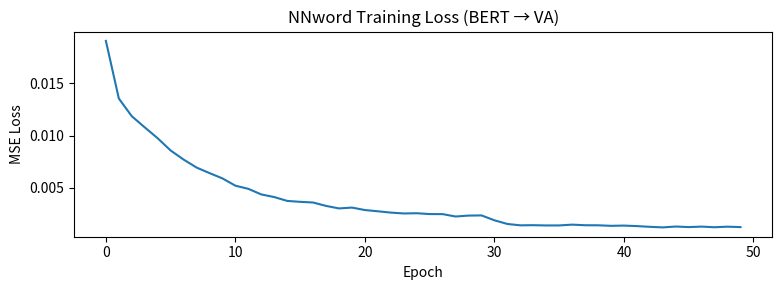

Stage 1 完成


In [ ]:
from torch.utils.data import TensorDataset, DataLoader
model_word = NNword(BERT_DIM).to(device)
opt_word   = optim.AdamW(model_word.parameters(), lr=1e-3, weight_decay=0.01)
sch_word   = optim.lr_scheduler.StepLR(opt_word, step_size=30, gamma=0.5)
# DataLoader（batch training 讓 BatchNorm 正常運作）
word_ds = TensorDataset(wt_v, wt_y_v, wt_y_a)
word_dl = DataLoader(word_ds, batch_size=64, shuffle=True)
print('=== Stage 1：訓練 NNword ===')
N_EPOCHS_WORD = 50
losses_w = []
for epoch in range(N_EPOCHS_WORD):
    model_word.train()
    epoch_loss = 0.0
    for bvec, by_v, by_a in word_dl:
        pred_v, pred_a = model_word(bvec)
        loss = 0.5 * ((pred_v - by_v)**2 + (pred_a - by_a)**2).mean()
        opt_word.zero_grad()
        loss.backward()
        opt_word.step()
        epoch_loss += loss.item()
    sch_word.step()
    avg = epoch_loss / len(word_dl)
    losses_w.append(avg)
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_WORD} | Loss: {avg:.6f}')
plt.figure(figsize=(8,3))
plt.plot(losses_w)
plt.title('NNword Training Loss (BERT → VA)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()
print('Stage 1 完成')

## 7. Stage 2：訓練 NNmod（NNword 凍結，直接訓練遞迴鏈）
**v7-2 遞迴鏈訓練流程：**
1. NNword(BERT(core_word)) → Int(w)
2. 由最靠近核心詞的修飾詞開始，逐層遞迴：
   NNmod(Int(current), BERT(modifier [SEP] current_phrase))
3. 以最終 Int(full_phrase) 對齊片語標註 VA
NNword 仍凍結，只訓練 NNmod；但現在訓練時就會展開多層鏈。

=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===
流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)
Epoch  20/100 | Loss: 0.003995
Epoch  40/100 | Loss: 0.002619
Epoch  60/100 | Loss: 0.001992
Epoch  80/100 | Loss: 0.001540
Epoch 100/100 | Loss: 0.001396


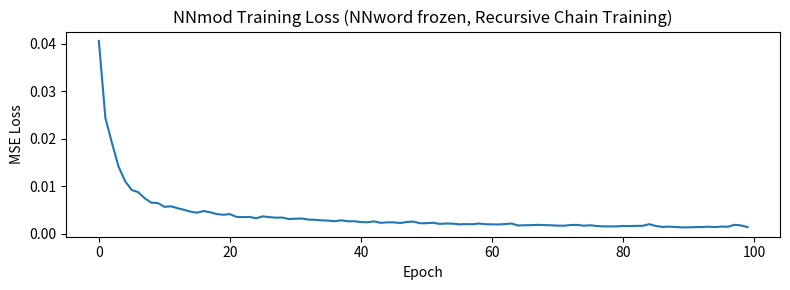

Stage 2 完成


In [ ]:
model_mod = NNmod(BERT_DIM).to(device)
# 凍結 NNword
for param in model_word.parameters():
    param.requires_grad = False
opt_mod = optim.AdamW(model_mod.parameters(), lr=3e-3, weight_decay=1e-4)
print('=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===')
print('流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)')
N_EPOCHS_MOD = 100
losses_m = []
grad_accum_steps = 16
for epoch in range(N_EPOCHS_MOD):
    model_mod.train()
    model_word.eval()
    epoch_loss = 0.0
    idxs = np.random.permutation(len(train_chain_samples))
    opt_mod.zero_grad()
    for step_i, si in enumerate(idxs, start=1):
        s = train_chain_samples[si]
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        # Step 1：核心詞先經 NNword（固定）
        with torch.no_grad():
            cur_v, cur_a = model_word(core_t)
        # Step 2：沿遞迴鏈逐步套用 NNmod（每步語境都不同）
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, _ = model_mod(cur_v, cur_a, ctx_t)
        # 只用最終 full phrase 監督
        loss = 0.5 * ((cur_v - y_v)**2 + (cur_a - y_a)**2).mean()
        (loss / grad_accum_steps).backward()
        epoch_loss += loss.item()
        if (step_i % grad_accum_steps == 0) or (step_i == len(idxs)):
            torch.nn.utils.clip_grad_norm_(model_mod.parameters(), max_norm=1.0)
            opt_mod.step()
            opt_mod.zero_grad()
    avg = epoch_loss / len(train_chain_samples)
    losses_m.append(avg)
    if (epoch + 1) % 20 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_MOD} | Loss: {avg:.6f}')
plt.figure(figsize=(8,3))
plt.plot(losses_m)
plt.title('NNmod Training Loss (NNword frozen, Recursive Chain Training)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()
print('Stage 2 完成')

## 8. 預測函式

In [ ]:
@torch.no_grad()
def predict_word_va(word):
    """
    單詞 VA 預測：BERT encode → NNword → (valence, arousal)
    """
    model_word.eval()
    vec = torch.tensor(get_bert_vec(word)).unsqueeze(0).to(device)
    val, aro = model_word(vec)
    return val.item(), aro.item()
@torch.no_grad()
def predict_phrase_va_pipeline(modifier, core_word, verbose=False):
    """
    單層 Pipeline 預測（語境化修飾詞）：
    BERT(core_word) → NNword → Int(w)
    BERT(modifier [SEP] core_word) → NNmod → Int(mod w)
    """
    model_word.eval()
    model_mod.eval()
    # Step 1：核心詞 BERT encode → NNword → Int(w)
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    int_val, int_aro = model_word(core_vec)
    # Step 2：語境化修飾詞 BERT encode → NNmod
    mod_ctx_vec = torch.tensor(get_bert_pair_vec(modifier, core_word)).unsqueeze(0).to(device)
    pred_v, pred_a, c_mod_v, c_mod_a = model_mod(int_val, int_aro, mod_ctx_vec)
    pv, pa = pred_v.item(), pred_a.item()
    iv, ia = int_val.item(), int_aro.item()
    cmv = c_mod_v.item()
    cma = c_mod_a.item()
    if verbose:
        print(f'「{modifier}{core_word}」'
              f'  base(V={iv:.3f},A={ia:.3f})'
              f'  Cmod(V={cmv:.3f},A={cma:.3f})'
              f'  → V={pv:.4f} A={pa:.4f}')
    return pv, pa, cmv, cma
def va_label(v, a):
    pol = '正向' if v>=0.625 else ('負向' if v<=0.375 else '中性')
    act = '高喚起' if a>=0.625 else ('低喚起' if a<=0.375 else '中喚起')
    return f'{pol}/{act}'
# 測試預測
print('=== 單詞預測 ===')
for w in ['開心','難過','憤怒','平靜','興奮','恐懼']:
    v, a = predict_word_va(w)
    print(f'「{w}」V={v:.4f} A={a:.4f} → {va_label(v,a)}')
print()
print('=== Pipeline 片語預測 ===')
for mod, word in [('非常','開心'),('沒有','希望'),('完全','不滿意'),
                  ('極為','不安'),('相當','平靜'),('可能','失望')]:
    pv, pa, cmv, cma = predict_phrase_va_pipeline(mod, word, verbose=True)
    print(f'  → {va_label(pv, pa)} | Cmod(V={cmv:.3f}, A={cma:.3f})')

=== 單詞預測 ===
「開心」V=0.7743 A=0.7120 → 正向/高喚起
「難過」V=0.2572 A=0.5971 → 負向/中喚起
「憤怒」V=0.1686 A=0.7831 → 負向/高喚起
「平靜」V=0.6800 A=0.1923 → 正向/低喚起
「興奮」V=0.7917 A=0.7942 → 正向/高喚起
「恐懼」V=0.2109 A=0.7471 → 負向/高喚起

=== Pipeline 片語預測 ===
「非常開心」  base(V=0.774,A=0.712)  Cmod(V=0.812,A=0.737)  → V=0.8974 A=0.8341
  → 正向/高喚起 | Cmod(V=0.812, A=0.737)
「沒有希望」  base(V=0.726,A=0.495)  Cmod(V=0.001,A=0.473)  → V=0.3725 A=0.4753
  → 負向/中喚起 | Cmod(V=0.001, A=0.473)
「完全不滿意」  base(V=0.381,A=0.354)  Cmod(V=0.273,A=0.710)  → V=0.2376 A=0.5069
  → 負向/中喚起 | Cmod(V=0.273, A=0.710)
「極為不安」  base(V=0.346,A=0.558)  Cmod(V=0.218,A=0.731)  → V=0.1851 A=0.7165
  → 負向/高喚起 | Cmod(V=0.218, A=0.731)
「相當平靜」  base(V=0.680,A=0.192)  Cmod(V=0.614,A=0.487)  → V=0.7495 A=0.1863
  → 正向/低喚起 | Cmod(V=0.614, A=0.487)
「可能失望」  base(V=0.253,A=0.568)  Cmod(V=0.327,A=0.587)  → V=0.1678 A=0.6308
  → 負向/高喚起 | Cmod(V=0.327, A=0.587)


## 9. 多修飾詞遞迴預測（論文 Fig. 4）
每層輸出 VA 傳入下一層，逐層套用修飾詞。  
v7-2 在每一層都用 `BERT(modifier [SEP] 當前片語)` 重新編碼，
避免同一個副詞在不同語境得到完全相同表示。

In [ ]:
@torch.no_grad()
def predict_multi_mod_pipeline(modifiers, core_word):
    """
    多修飾詞遞迴 Pipeline（對應論文 Fig. 4）：
    由最靠近核心詞的修飾詞（列表最右）開始，逐層向外套用。
    語境化版本：每層使用 BERT(modifier [SEP] 當前片語)
    """
    model_word.eval()
    model_mod.eval()
    phrase_str = ''.join(modifiers) + core_word
    print(f'\n多修飾詞遞迴：「{phrase_str}」')
    # 第一步：核心詞走 BERT + NNword
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    cur_v, cur_a = model_word(core_vec)
    print(f'  核心詞「{core_word}」→ V={cur_v.item():.4f} A={cur_a.item():.4f}')
    cur_label = core_word
    # 從最靠近核心詞的修飾詞開始，逐層向外（reversed）
    for i, mod in enumerate(reversed(modifiers)):
        mod_ctx_vec = torch.tensor(get_bert_pair_vec(mod, cur_label)).unsqueeze(0).to(device)
        new_v, new_a, c_mod_v, c_mod_a = model_mod(cur_v, cur_a, mod_ctx_vec)
        print(f'  +「{mod}」[mod_{len(modifiers)-i}] '
              f'V:{cur_v.item():.4f}→{new_v.item():.4f}  '
              f'A:{cur_a.item():.4f}→{new_a.item():.4f}  '
              f'[Cv={c_mod_v.item():.3f}, Ca={c_mod_a.item():.3f}]')
        cur_v, cur_a = new_v, new_a
        cur_label = mod + cur_label
    final_v, final_a = cur_v.item(), cur_a.item()
    print(f'  最終「{phrase_str}」→ V={final_v:.4f} A={final_a:.4f}  {va_label(final_v, final_a)}')
    return final_v, final_a
# 測試（對應論文 Fig. 4 的 would not very good）
predict_multi_mod_pipeline(['應該','沒有','非常'], '開心')
predict_multi_mod_pipeline(['完全','不'],          '滿意')
predict_multi_mod_pipeline(['可能','更加'],        '不安')


多修飾詞遞迴：「應該沒有非常開心」
  核心詞「開心」→ V=0.7743 A=0.7120
  +「非常」[mod_3] V:0.7743→0.8974  A:0.7120→0.8341  [Cv=0.812, Ca=0.737]
  +「沒有」[mod_2] V:0.8974→0.6618  A:0.8341→0.6286  [Cv=0.001, Ca=0.137]
  +「應該」[mod_1] V:0.6618→0.5083  A:0.6286→0.5798  [Cv=0.287, Ca=0.432]
  最終「應該沒有非常開心」→ V=0.5083 A=0.5798  中性/中喚起

多修飾詞遞迴：「完全不滿意」
  核心詞「滿意」→ V=0.6568 A=0.5194
  +「不」[mod_2] V:0.6568→0.3020  A:0.5194→0.5631  [Cv=0.004, Ca=0.559]
  +「完全」[mod_1] V:0.3020→0.1812  A:0.5631→0.6875  [Cv=0.276, Ca=0.678]
  最終「完全不滿意」→ V=0.1812 A=0.6875  負向/高喚起

多修飾詞遞迴：「可能更加不安」
  核心詞「不安」→ V=0.3461 A=0.5584
  +「更加」[mod_2] V:0.3461→0.2025  A:0.5584→0.6566  [Cv=0.255, Ca=0.638]
  +「可能」[mod_1] V:0.2025→0.2052  A:0.6566→0.6585  [Cv=0.506, Ca=0.503]
  最終「可能更加不安」→ V=0.2052 A=0.6585  負向/高喚起


(0.20520955324172974, 0.6585164666175842)

## 10. 評估函式

In [ ]:
def compute_metrics(preds, golds, label):
    """
    Chinese EmoBank 論文指標：MAE、Pearson r
    Pipelined NN 論文指標：Kendall τ、Spearman ρ
    額外：MSE
    """
    p = np.array(preds); g = np.array(golds)
    mae    = np.mean(np.abs(p - g))
    mse    = np.mean((p - g) ** 2)
    r, _   = pearsonr(p, g)
    tau, _ = kendalltau(p, g)
    rho, _ = spearmanr(p, g)
    print(f'  {label:30s} | MAE={mae:.4f}  MSE={mse:.4f}  r={r:.4f}  τ={tau:.4f}  ρ={rho:.4f}')
    return mae, mse, r, tau, rho
@torch.no_grad()
def batch_predict_word(vecs_np):
    model_word.eval()
    t = torch.tensor(vecs_np).to(device)
    pv, pa = model_word(t)
    return pv.cpu().numpy().flatten(), pa.cpu().numpy().flatten()
@torch.no_grad()
def batch_predict_phrase_recursive(samples, return_shift=False):
    """
    用與 Stage 2 相同的遞迴鏈路徑評估：
    core -> NNword -> NNmod(step1..stepN)
    """
    model_word.eval(); model_mod.eval()
    all_pv, all_pa = [], []
    all_cmv, all_cma = [], []
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        last_cmv = torch.tensor([[0.5]], device=device)
        last_cma = torch.tensor([[0.5]], device=device)
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, last_cmv, last_cma = model_mod(cur_v, cur_a, ctx_t)
        all_pv.append(cur_v.item())
        all_pa.append(cur_a.item())
        all_cmv.append(last_cmv.item())
        all_cma.append(last_cma.item())
    pv = np.array(all_pv, dtype=np.float32)
    pa = np.array(all_pa, dtype=np.float32)
    if return_shift:
        cmv = np.array(all_cmv, dtype=np.float32)
        cma = np.array(all_cma, dtype=np.float32)
        return pv, pa, cmv, cma
    return pv, pa

## 11. 訓練集評估

In [ ]:
print('='*75)
print('【訓練集評估】')
print('='*75)
# NNword 訓練集
print('\n[NNword] CVAW 訓練集')
pv_trw, pa_trw = batch_predict_word(word_train_vecs)
compute_metrics(pv_trw, word_train_val, 'Valence')
compute_metrics(pa_trw, word_train_aro, 'Arousal')
# Pipeline 訓練集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 訓練集')
pv_trm, pa_trm = batch_predict_phrase_recursive(train_chain_samples)
compute_metrics(pv_trm, phrase_train_val, 'Valence')
compute_metrics(pa_trm, phrase_train_aro, 'Arousal')

【訓練集評估】

[NNword] CVAW 訓練集
  Valence                        | MAE=0.0164  MSE=0.0005  r=0.9954  τ=0.9452  ρ=0.9942
  Arousal                        | MAE=0.0183  MSE=0.0006  r=0.9921  τ=0.9342  ρ=0.9922

[Pipeline-Recursive] CVAP 訓練集
  Valence                        | MAE=0.0257  MSE=0.0015  r=0.9859  τ=0.9081  ρ=0.9826
  Arousal                        | MAE=0.0201  MSE=0.0007  r=0.9855  τ=0.8948  ρ=0.9839


(np.float32(0.020122806),
 np.float32(0.0006835107),
 np.float32(0.9855137),
 np.float64(0.8948010953632942),
 np.float64(0.9838700906923044))

## 12. 測試集評估

In [ ]:
print('='*75)
print('【測試集評估】')
print('='*75)
# NNword 測試集
print('\n[NNword] CVAW 測試集')
pv_tew, pa_tew = batch_predict_word(word_test_vecs)
compute_metrics(pv_tew, word_test_val, 'Valence')
compute_metrics(pa_tew, word_test_aro, 'Arousal')
# Pipeline 測試集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 測試集')
pv_tem, pa_tem = batch_predict_phrase_recursive(test_chain_samples)
compute_metrics(pv_tem, phrase_test_val, 'Valence')
compute_metrics(pa_tem, phrase_test_aro, 'Arousal')

【測試集評估】

[NNword] CVAW 測試集
  Valence                        | MAE=0.0735  MSE=0.0095  r=0.8800  τ=0.6658  ρ=0.8501
  Arousal                        | MAE=0.1107  MSE=0.0202  r=0.6213  τ=0.4350  ρ=0.6020

[Pipeline-Recursive] CVAP 測試集
  Valence                        | MAE=0.0536  MSE=0.0054  r=0.9425  τ=0.7970  ρ=0.9393
  Arousal                        | MAE=0.0528  MSE=0.0044  r=0.9029  τ=0.7147  ρ=0.8914


(np.float32(0.052779507),
 np.float32(0.0044473056),
 np.float32(0.9028591),
 np.float64(0.7146877158296415),
 np.float64(0.8914339153503514))

## 13. 結果摘要表 + 視覺化

In [ ]:
def metrics(p, g):
    pa = np.array(p); ga = np.array(g)
    mae    = np.mean(np.abs(pa - ga))
    mse    = np.mean((pa - ga)**2)
    r, _   = pearsonr(pa, ga)
    tau, _ = kendalltau(pa, ga)
    rho, _ = spearmanr(pa, ga)
    return round(mae,4), round(mse,4), round(r,4), round(tau,4), round(rho,4)
rows = [
    ('NNword',   '訓練', 'Valence', *metrics(pv_trw, word_train_val)),
    ('NNword',   '訓練', 'Arousal', *metrics(pa_trw, word_train_aro)),
    ('NNword',   '測試', 'Valence', *metrics(pv_tew, word_test_val)),
    ('NNword',   '測試', 'Arousal', *metrics(pa_tew, word_test_aro)),
    ('Pipeline', '訓練', 'Valence', *metrics(pv_trm, phrase_train_val)),
    ('Pipeline', '訓練', 'Arousal', *metrics(pa_trm, phrase_train_aro)),
    ('Pipeline', '測試', 'Valence', *metrics(pv_tem, phrase_test_val)),
    ('Pipeline', '測試', 'Arousal', *metrics(pa_tem, phrase_test_aro)),
]
summary = pd.DataFrame(rows,
    columns=['模型','資料集','維度','MAE','MSE','Pearson r','Kendall τ','Spearman ρ'])
print(summary.to_string(index=False))

      模型 資料集      維度    MAE    MSE  Pearson r  Kendall τ  Spearman ρ
  NNword  訓練 Valence 0.0164 0.0005     0.9954     0.9452      0.9942
  NNword  訓練 Arousal 0.0183 0.0006     0.9921     0.9342      0.9922
  NNword  測試 Valence 0.0735 0.0095     0.8800     0.6658      0.8501
  NNword  測試 Arousal 0.1107 0.0202     0.6213     0.4350      0.6020
Pipeline  訓練 Valence 0.0257 0.0015     0.9859     0.9081      0.9826
Pipeline  訓練 Arousal 0.0201 0.0007     0.9855     0.8948      0.9839
Pipeline  測試 Valence 0.0536 0.0054     0.9425     0.7970      0.9393
Pipeline  測試 Arousal 0.0528 0.0044     0.9029     0.7147      0.8914


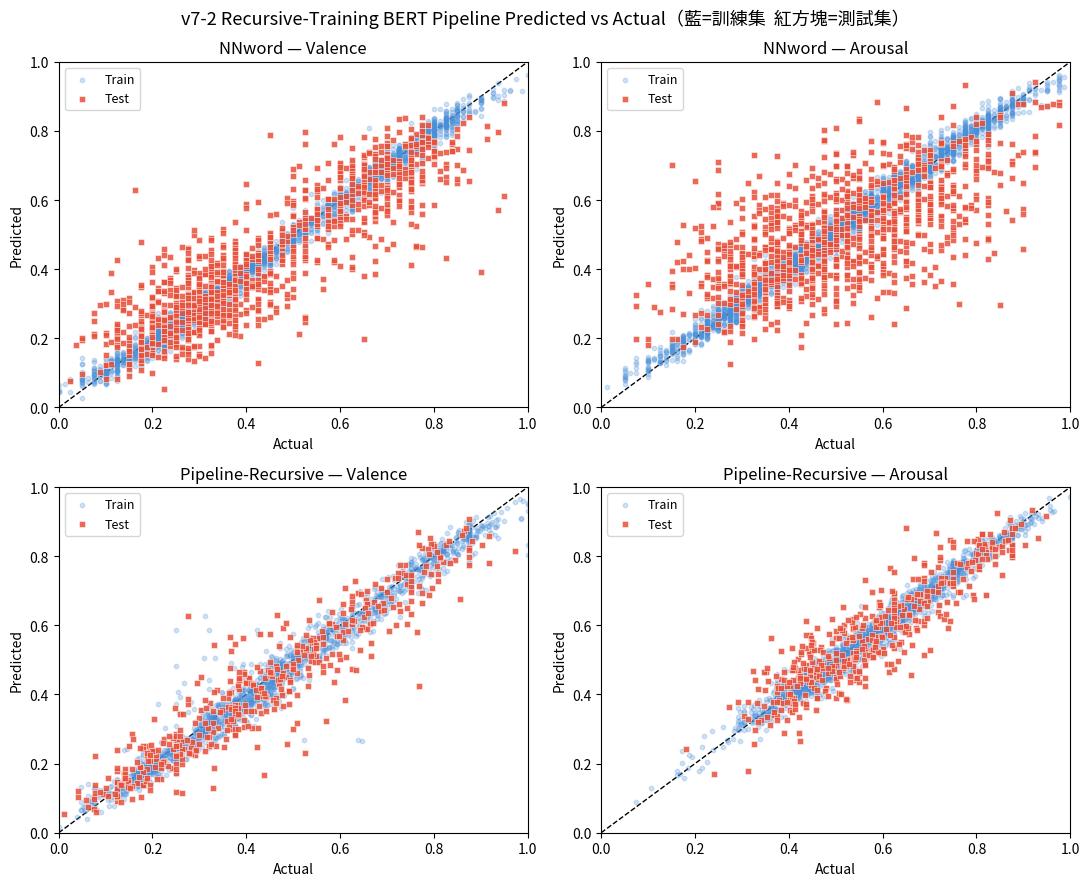

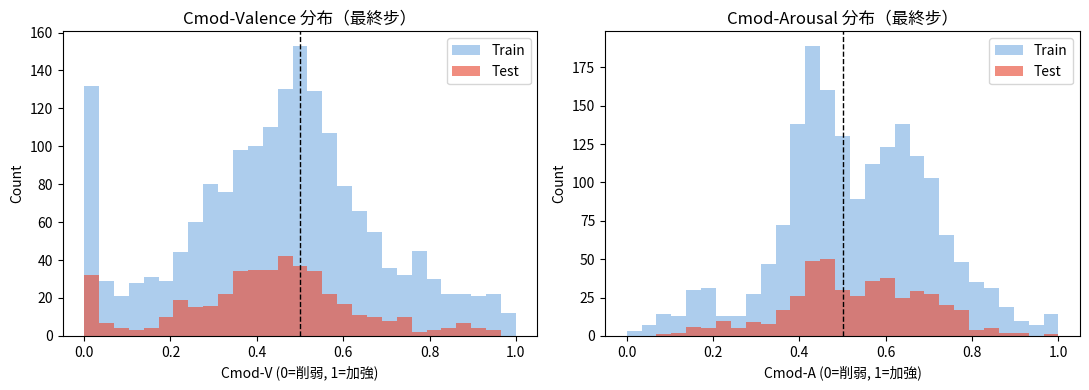

Test Cmod-V mean=0.424, std=0.206
Test Cmod-A mean=0.531, std=0.157


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
fig.suptitle('v7-2 Recursive-Training BERT Pipeline Predicted vs Actual（藍=訓練集  紅方塊=測試集）', fontsize=13)
configs = [
    (axes[0,0], pv_trw, word_train_val, pv_tew, word_test_val, 'NNword — Valence',   '#4A90D9', '#E8503A'),
    (axes[0,1], pa_trw, word_train_aro, pa_tew, word_test_aro, 'NNword — Arousal',   '#4A90D9', '#E8503A'),
    (axes[1,0], pv_trm, phrase_train_val, pv_tem, phrase_test_val, 'Pipeline-Recursive — Valence', '#4A90D9', '#E8503A'),
    (axes[1,1], pa_trm, phrase_train_aro, pa_tem, phrase_test_aro, 'Pipeline-Recursive — Arousal', '#4A90D9', '#E8503A'),
]
for ax, ptr, gtr, pte, gte, title, c_tr, c_te in configs:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color=c_tr, label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color=c_te, marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0,1],[0,1],'k--', linewidth=1, zorder=1)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()
# c_mod 雙維度視覺化（Valence shift / Arousal shift）
_, _, cmv_tr, cma_tr = batch_predict_phrase_recursive(train_chain_samples, return_shift=True)
_, _, cmv_te, cma_te = batch_predict_phrase_recursive(test_chain_samples, return_shift=True)
fig2, axes2 = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0.0, 1.0, 30)
axes2[0].hist(cmv_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[0].hist(cmv_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[0].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[0].set_title('Cmod-Valence 分布（最終步）')
axes2[0].set_xlabel('Cmod-V (0=削弱, 1=加強)')
axes2[0].set_ylabel('Count')
axes2[0].legend()
axes2[1].hist(cma_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[1].hist(cma_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[1].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[1].set_title('Cmod-Arousal 分布（最終步）')
axes2[1].set_xlabel('Cmod-A (0=削弱, 1=加強)')
axes2[1].set_ylabel('Count')
axes2[1].legend()
plt.tight_layout(); plt.show()
print(f'Test Cmod-V mean={cmv_te.mean():.3f}, std={cmv_te.std():.3f}')
print(f'Test Cmod-A mean={cma_te.mean():.3f}, std={cma_te.std():.3f}')

## [新增] NNword / NNmod 預測 VA 分布散佈圖（仿論文 Fig. 3 樣式）

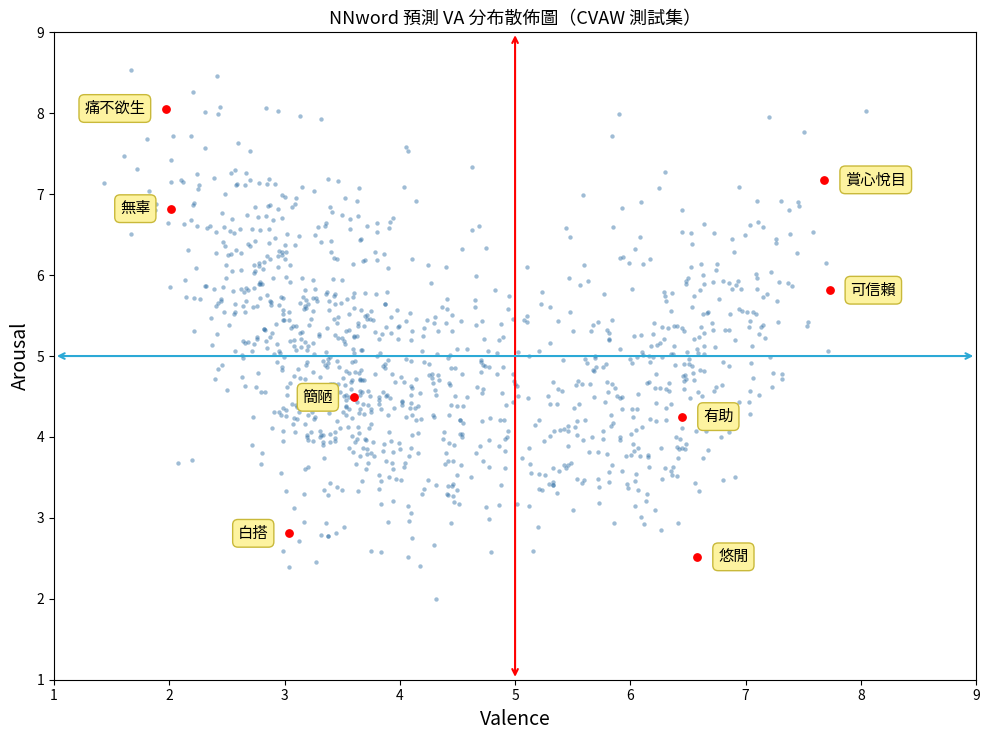

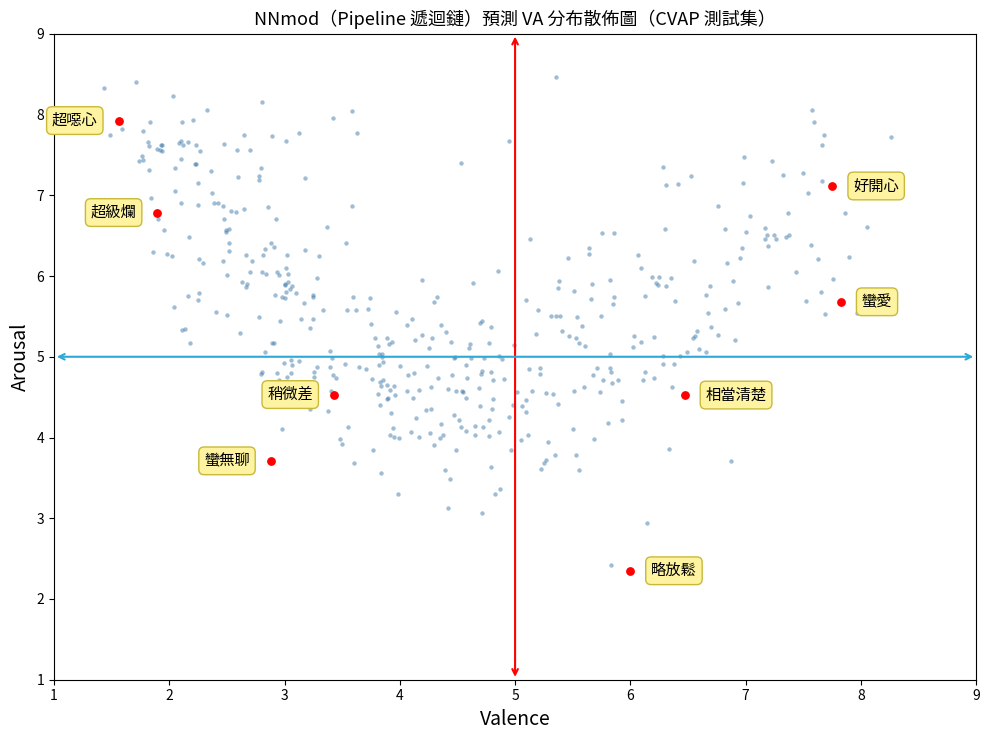

In [ ]:
plot_va_scatter(pv_tew, pa_tew, cvaw_test['Word'].tolist(),
                'NNword 預測 VA 分布散佈圖（CVAW 測試集）', savepath='nnword_va_scatter.png')
plot_va_scatter(pv_tem, pa_tem, [s['full_phrase'] for s in test_chain_samples],
                'NNmod（Pipeline 遞迴鏈）預測 VA 分布散佈圖（CVAP 測試集）', savepath='nnmod_va_scatter.png')

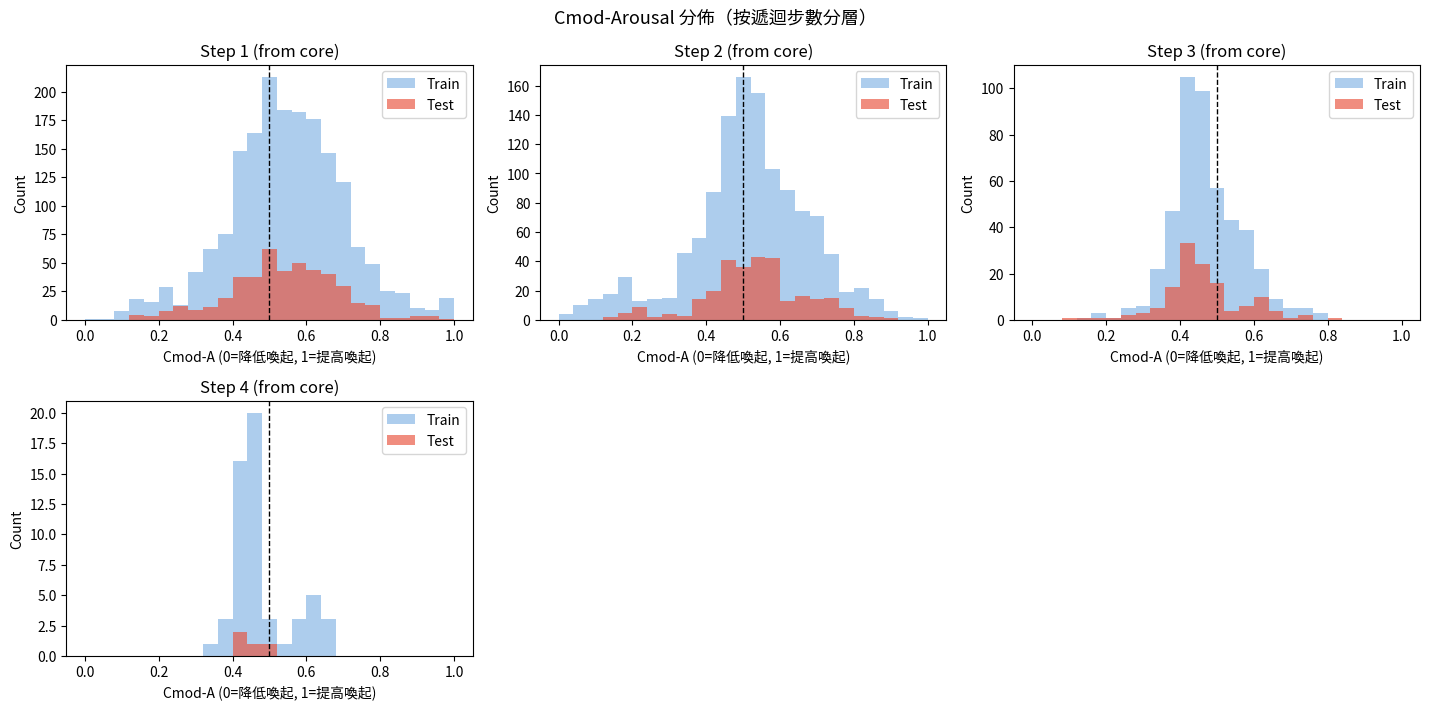

=== 每一步 Cmod-A 統計（Test）===
Step 1: mean=0.538, std=0.145, n=450
Step 2: mean=0.529, std=0.139, n=293
Step 3: mean=0.460, std=0.113, n=129
Step 4: mean=0.456, std=0.021, n=4


In [ ]:
@torch.no_grad()
def collect_cmod_a_by_step(samples):
    model_word.eval()
    model_mod.eval()
    step_to_vals = {}
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        for step_idx, ctx_np in enumerate(s['ctx_chain'], start=1):
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, c_mod_a = model_mod(cur_v, cur_a, ctx_t)
            step_to_vals.setdefault(step_idx, []).append(c_mod_a.item())
    return {k: np.array(v, dtype=np.float32) for k, v in step_to_vals.items()}

train_a_by_step = collect_cmod_a_by_step(train_chain_samples)
test_a_by_step = collect_cmod_a_by_step(test_chain_samples)
all_steps = sorted(set(train_a_by_step.keys()) | set(test_a_by_step.keys()))
if not all_steps:
    raise ValueError('沒有可用的遞迴步數資料，請先確認 train_chain_samples / test_chain_samples。')
n_steps = len(all_steps)
n_cols = min(3, n_steps)
n_rows = int(np.ceil(n_steps / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.8 * n_cols, 3.6 * n_rows), squeeze=False)
bins = np.linspace(0.0, 1.0, 26)
for i, step in enumerate(all_steps):
    r = i // n_cols
    c = i % n_cols
    ax = axes[r, c]
    tr = train_a_by_step.get(step, np.array([], dtype=np.float32))
    te = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(tr) > 0:
        ax.hist(tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
    if len(te) > 0:
        ax.hist(te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
    ax.axvline(0.5, color='k', linestyle='--', linewidth=1)
    ax.set_title(f'Step {step} (from core)')
    ax.set_xlabel('Cmod-A (0=降低喚起, 1=提高喚起)')
    ax.set_ylabel('Count')
    ax.legend()
for j in range(n_steps, n_rows * n_cols):
    rr = j // n_cols
    cc = j % n_cols
    axes[rr, cc].axis('off')
fig.suptitle('Cmod-Arousal 分佈（按遞迴步數分層）', fontsize=13)
plt.tight_layout()
plt.show()
print('=== 每一步 Cmod-A 統計（Test）===')
for step in all_steps:
    vals = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(vals) == 0:
        continue
    print(f'Step {step}: mean={vals.mean():.3f}, std={vals.std():.3f}, n={len(vals)}')

## 14. Stage 3（v8-UniCtx）：統一語境的句子層級 NNsent（NNword / NNmod 完全不動，僅新增）

**這一版是依最近一次教授會議結論，把 v7-3c 的 Stage 3 整個改寫簡化的版本。**
Stage 1（NNword）、Stage 2（NNmod）以及前面 0–13 節跟 v7-2 完全相同，沒有任何改動。

**教授三點意見 → 這一版怎麼對應：**

1. **「太複雜，hit=0 不要特殊處理，VA 要參考整句語境」** →
   不管 span 有沒有修飾詞，**每一個 span 都走同一條路**：
   `BERT(span [SEP] 整句)` 取得語境向量 → 同一個 `SpanContextAdapter` 修正 → 同一個遞迴 `NNsent.step()`。
   `hit` 從「決定走哪段程式」降級成「一個 0/1 輸入特徵」。
   v7-3c 裡 `run_full_pipeline` 的 mod / core / fallback 三種 kind 分支、以及 `NNsent.forward()` 裡
   `if ctx is not None: ... else: ...` 的分支，全部拿掉。
2. **「沒看過的字跟看過的字應該走一樣的路，用向量相近判斷這個字有沒有情緒貢獻」** →
   對**任何**詞（CVAW 訓練詞＝看過、CVAW 測試詞＝沒看過、完全不在 CVAW 的詞）都用同一個公式：
   取它的 BERT 向量，到「看過的詞」（`cvaw_train`）裡找 top-k 最近鄰，得到
   ① 鄰居加權 VA（`knn_v, knn_a`）、② 相似度（`conf_mean, conf_max`＝「像不像看過的情緒詞」）。
   看過的詞在查詢時排除自己（leave-one-out），所以兩種詞的特徵分布一致，不會因為「自己找到自己」而走不同的路。
   `conf` 同時用在兩個地方：gate 決定要相信 NNword 還是鄰居、以及（可選）決定一個 CVAW 以外的詞
   要不要被當成情緒 span 收進來（`UNICTX_OOV_SPANS`）。
3. **「NNword 在沒看過的字效果也不好」** → 14.2b 在訓練句子層之前，先用 `cvaw_test`
   量化比較 NNword／鄰居傳播／兩者混合，以及 `conf` 能不能預測 NNword 的誤差（教授那個假設的直接檢驗）。

**另一個順手修掉的 bug（重要）：** v7-2 的 `get_bert_vec` 是 `max_length=16`。v7-3b/3c 的「整句向量」
就是拿它算的，所以所謂「整句語境」其實只看到**句子最前面約 14 個字**。v8 改用 `max_length=128` 的
`BERT(span [SEP] sentence)`，語境才是真的整句。

**消融開關（論文可直接用來做 ablation）：**
`UNICTX_USE_KNN=False` → 只做第 1 點（統一路徑，沒有鄰近度特徵）；
`UNICTX_USE_KNN=True, UNICTX_OOV_SPANS=False` → 第 1+2 點（只對 CVAW 詞做鄰近度 gate）；
兩者皆 True → 完整版（CVAW 以外的詞也能因為「像看過的情緒詞」被收進來）。

### 14.0 設定與開關

In [ ]:
import re, copy, sys, subprocess
from scipy.stats import spearmanr as _spearmanr

# ---- v8-UniCtx 開關 / 超參數 ----
UNICTX_USE_KNN   = True    # 是否使用「鄰近度傳播 + gate」（第 2 點）
UNICTX_OOV_SPANS = True    # 是否讓「不在 CVAW 的詞」依鄰近度被收進來當 span（需要 jieba）
KNN_K        = 10          # 取幾個最近鄰
KNN_TEMP     = 0.05        # 鄰居 softmax 加權的溫度（越小越偏向最像的那一個）
OOV_SIM_PCT  = 25          # 門檻 = 「看過的詞」leave-one-out 相似度分布的第幾百分位
MAX_SPANS    = 8           # 一句最多取幾個 span
MOD_WINDOW   = 6           # 情感詞往前找修飾詞的視窗大小（字數）
SENT_MAXLEN  = 128         # BERT(span [SEP] sentence) 的最大長度（v7 只有 16，會把整句截掉）
SEED         = 42          # 固定隨機種子，ablation 比較才公平（v7 沒有設）

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    import jieba
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'jieba'], check=False)
    try:
        import jieba
    except ImportError:
        jieba = None
if UNICTX_OOV_SPANS and jieba is None:
    print('⚠ 找不到 jieba，自動關閉 UNICTX_OOV_SPANS（只處理 CVAW 內的詞）')
    UNICTX_OOV_SPANS = False

print(f'UNICTX_USE_KNN={UNICTX_USE_KNN}  UNICTX_OOV_SPANS={UNICTX_OOV_SPANS}  '
      f'K={KNN_K}  T={KNN_TEMP}  OOV_SIM_PCT={OOV_SIM_PCT}  SENT_MAXLEN={SENT_MAXLEN}')

/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:44: SyntaxWarning: invalid escape sequence '\.'
  re_han_default = re.compile("([\u4E00-\u9FD5a-zA-Z0-9+#&\._%\-]+)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:46: SyntaxWarning: invalid escape sequence '\s'
  re_skip_default = re.compile("(\r\n|\s)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/finalseg/__init__.py:78: SyntaxWarning: invalid escape sequence '\.'
  re_skip = re.compile("([a-zA-Z0-9]+(?:\.\d+)?%?)")
/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


UNICTX_USE_KNN=True  UNICTX_OOV_SPANS=True  K=10  T=0.05  OOV_SIM_PCT=25  SENT_MAXLEN=128


### 14.1 CVAS 前處理（正規化 + 切分，沿用 `normalize_va`，不重新定義）

In [ ]:
cvas = normalize_va(cvas)
cvas_train_full, cvas_test = train_test_split(cvas, test_size=0.2, random_state=42)
# 再從訓練集切一份驗證集：完全不參與梯度更新，只用來監控 overfitting 與挑最佳 epoch；
# cvas_test 維持完全不動，只在全部訓練結束後看一次。
cvas_train, cvas_val = train_test_split(cvas_train_full, test_size=0.15, random_state=42)
print(f'CVAS 訓練:{len(cvas_train)}  驗證:{len(cvas_val)}  測試:{len(cvas_test)}')
print(cvas_train[['Text', 'valence', 'arousal']].head().to_string(index=False))

CVAS 訓練:1756  驗證:310  測試:517
              Text  valence  arousal
整個官僚機制和國民內鬥的齒輪咬合咬合 0.312500 0.625000
           王岐山器重明鏡 0.625000 0.312500
        偶爾在陰雨綿綿的夜晚 0.425000 0.281250
         如果我果斷獨自沉澱 0.416625 0.333375
       但情人海灘仍然美得驚人 0.875000 0.800000


### 14.2a 「看過的詞」鄰居索引（第 2 點：對所有詞用同一套公式）

「看過的詞」＝ NNword 訓練時用過的 `cvaw_train`。BERT 的單詞 `[CLS]` 向量彼此的 cosine 普遍很高
（各向異性），所以先減掉「看過的詞」的平均向量再算 cosine，相似度才拉得開。

查詢任何一個詞 `w` 都是同一個函式 `lex_nb.query(w)`：
- 回傳 `(knn_v, knn_a, conf_mean, conf_max)`；
- 若 `w` 本身就在「看過的詞」裡，查詢時**把自己排除**（leave-one-out），
  這樣看過的詞和沒看過的詞拿到的特徵分布一致，模型不會學到「相似度=1 才可信」這種對沒看過的詞無效的捷徑。

In [ ]:
def prefetch_core_vecs(words, batch_size=64):
    """把還沒快取的詞一次批次算好 BERT 單詞向量，放進 core_cache（比逐個算快很多）。"""
    missing = [w for w in dict.fromkeys(words) if w not in core_cache]
    if not missing:
        return
    vecs = get_bert_vecs_batch(missing, batch_size=batch_size)
    for w, v in zip(missing, vecs):
        core_cache[w] = v


class LexiconNeighbors:
    """對「看過的詞」建 cosine 近鄰索引；query(word) 對任何詞都走同一條路。"""
    def __init__(self, words, vecs, va_v, va_a, k=10, temp=0.05):
        self.k, self.temp = k, temp
        self.words = [str(w) for w in words]
        self.word2idx = {}
        for i, w in enumerate(self.words):
            self.word2idx.setdefault(w, []).append(i)
        vecs = np.asarray(vecs, dtype=np.float32)
        self.mu = vecs.mean(axis=0, keepdims=True)
        P = vecs - self.mu
        P = P / (np.linalg.norm(P, axis=1, keepdims=True) + 1e-8)
        self.P = torch.tensor(P, dtype=torch.float32, device=device)
        self.v = torch.tensor(np.asarray(va_v, dtype=np.float32), device=device)
        self.a = torch.tensor(np.asarray(va_a, dtype=np.float32), device=device)
        self.cache = {}

    @torch.no_grad()
    def query(self, word):
        word = str(word)
        if word in self.cache:
            return self.cache[word]
        q = torch.tensor(get_core_vec_cached(word), dtype=torch.float32, device=device)[None, :]
        q = q - torch.tensor(self.mu, device=device)
        q = q / (q.norm(dim=1, keepdim=True) + 1e-8)
        sims = (self.P @ q[0])
        for i in self.word2idx.get(word, []):      # leave-one-out：看過的詞不能找到自己
            sims[i] = -1e9
        k = min(self.k, sims.numel() - 1)
        top = torch.topk(sims, k)
        w = torch.softmax(top.values / self.temp, dim=0)
        out = (float((w * self.v[top.indices]).sum()),
               float((w * self.a[top.indices]).sum()),
               float(top.values.mean()),
               float(top.values[0]))
        self.cache[word] = out
        return out


# 「看過的詞」= NNword 訓練用的 cvaw_train（word_train_vecs 就是它們的 BERT 向量，順序一致）
pool_words = cvaw_train['Word'].astype(str).tolist()
pool_set = set(pool_words)
prefetch_core_vecs(list(cvaw_word_set))          # CVAW 全部詞（含 cvaw_test）一次算好
lex_nb = LexiconNeighbors(pool_words, word_train_vecs, word_train_val, word_train_aro,
                          k=KNN_K, temp=KNN_TEMP)

# OOV 收進門檻：用「看過的詞」自己的 leave-one-out conf_mean 分布決定
_rng = np.random.RandomState(SEED)
_probe = _rng.choice(pool_words, size=min(2000, len(pool_words)), replace=False)
_loo_conf = np.array([lex_nb.query(w)[2] for w in _probe])
OOV_TAU = float(np.percentile(_loo_conf, OOV_SIM_PCT))
print(f'看過的詞 leave-one-out conf_mean：mean={_loo_conf.mean():.3f}  '
      f'p{OOV_SIM_PCT}={OOV_TAU:.3f}（OOV 詞 conf_mean ≥ 此門檻才會被收進來當 span）')


_nnword_cache = {}


@torch.no_grad()
def nnword_va(word):
    """NNword 對單一詞的 VA 估計（凍結、有快取）。"""
    if word not in _nnword_cache:
        model_word.eval()
        vec = torch.tensor(get_core_vec_cached(word)).unsqueeze(0).to(device)
        v, a = model_word(vec)
        _nnword_cache[word] = (v.item(), a.item())
    return _nnword_cache[word]

看過的詞 leave-one-out conf_mean：mean=0.572  p25=0.493（OOV 詞 conf_mean ≥ 此門檻才會被收進來當 span）


### 14.2b 診斷（教授第 3 點）：NNword 對「沒看過的字」到底有多差？鄰近度能不能補、`conf` 可不可信？

用 `cvaw_test`（NNword 訓練時完全沒看過的詞）檢查三件事：
① NNword 直接預測、② 只用鄰居傳播（SentProp 風格，但用 BERT 向量）、③ 兩者平均，各自跟標註的 Pearson r；
④ `conf_mean` 跟 NNword 絕對誤差的 Spearman ρ——如果是**負相關**，代表「向量跟看過的詞越像，NNword 越準」，
也就是教授說的「相似度可以拿來判斷這個字可不可信／有沒有情緒貢獻」這個假設成立。

In [ ]:
_test_words = cvaw_test['Word'].astype(str).tolist()
prefetch_core_vecs(_test_words)
_nw = np.array([nnword_va(w) for w in _test_words])                  # (n, 2)
_kq = np.array([lex_nb.query(w) for w in _test_words])               # (n, 4)
_gv = cvaw_test['valence'].values; _ga = cvaw_test['arousal'].values

def _r(x, y):
    return pearsonr(x, y)[0]

print('=== cvaw_test（NNword 沒看過的詞）Pearson r ===')
print(f'  {"":22s} {"Valence":>8s} {"Arousal":>8s}')
print(f'  {"NNword 直接預測":20s} {_r(_nw[:,0], _gv):8.4f} {_r(_nw[:,1], _ga):8.4f}')
print(f'  {"只用鄰居傳播(kNN)":18s} {_r(_kq[:,0], _gv):8.4f} {_r(_kq[:,1], _ga):8.4f}')
print(f'  {"兩者平均":22s} {_r((_nw[:,0]+_kq[:,0])/2, _gv):8.4f} {_r((_nw[:,1]+_kq[:,1])/2, _ga):8.4f}')

_err_v = np.abs(_nw[:, 0] - _gv); _err_a = np.abs(_nw[:, 1] - _ga)
_rho_v, _ = _spearmanr(_kq[:, 2], _err_v)
_rho_a, _ = _spearmanr(_kq[:, 2], _err_a)
print(f'\nconf_mean 與 NNword 絕對誤差的 Spearman ρ：Valence={_rho_v:+.3f}  Arousal={_rho_a:+.3f}')
print('  （負值＝越像「看過的詞」NNword 越準；接近 0＝相似度對可信度沒有幫助）')

# 依 conf 三等分，看 NNword 的誤差有沒有隨 conf 下降
_q1, _q2 = np.percentile(_kq[:, 2], [33.3, 66.7])
for name, m in [('conf 低（離看過的詞遠）', _kq[:, 2] <= _q1),
                ('conf 中', (_kq[:, 2] > _q1) & (_kq[:, 2] <= _q2)),
                ('conf 高（跟看過的詞很像）', _kq[:, 2] > _q2)]:
    print(f'  {name:22s} n={m.sum():4d}  NNword MAE  V={_err_v[m].mean():.4f}  A={_err_a[m].mean():.4f}')

=== cvaw_test（NNword 沒看過的詞）Pearson r ===
                          Valence  Arousal
  NNword 直接預測            0.8800   0.6213
  只用鄰居傳播(kNN)          0.8013   0.5518
  兩者平均                     0.8663   0.6263

conf_mean 與 NNword 絕對誤差的 Spearman ρ：Valence=-0.071  Arousal=-0.067
  （負值＝越像「看過的詞」NNword 越準；接近 0＝相似度對可信度沒有幫助）
  conf 低（離看過的詞遠）         n= 367  NNword MAE  V=0.0786  A=0.1164
  conf 中                 n= 369  NNword MAE  V=0.0712  A=0.1092
  conf 高（跟看過的詞很像）        n= 367  NNword MAE  V=0.0707  A=0.1064


### 14.2c 句子 → span 切割（所有 span 同一條路）

- **CVAW 內的詞**：跟 v7 一樣，掃描句子找 CVAW 詞，並往前找修飾詞鏈（行為不變，另外記下字元位置，才能排序）。
- **CVAW 以外的詞**（`UNICTX_OOV_SPANS=True`）：用 jieba 斷詞，對沒被上面涵蓋到、長度 ≥ 2 的中文詞，
  用 `lex_nb.query` 看它跟「看過的詞」像不像；`conf_mean ≥ OOV_TAU` 就收進來當 span（`kind='oov'`）。
  收進來之後**跟其他 span 完全同一條路**（NNword 先驗 → 鄰近度 → 整句語境 → 遞迴）。
- 沒有任何 span 時，退回把整句當一個 span（fallback，樣本極少）。

一個 span 的「meta」固定 11 維（全部 span 一樣）：
`[v0, a0, vw, aw, cmv, cma, hit, knn_v, knn_a, conf_mean, conf_max]`
（`v0/a0`＝NNword→NNmod 遞迴鏈算完的 VA；`vw/aw`＝核心詞單獨的 NNword；`hit`＝有沒有修飾詞，**只是特徵**）。

In [ ]:
_MODIFIER_SET = set(MODIFIER_LEXICON)
_CJK_ONLY = re.compile(r'^[一-鿿]+$')


def _lexicon_spans(sentence, mod_window=MOD_WINDOW):
    """CVAW 內的詞 + 修飾詞鏈（邏輯同 v7 的 extract_emotion_spans，另外回傳字元位置）。"""
    found, seen_texts = [], set()
    i = 0
    while i < len(sentence):
        matched_core, matched_len = None, 0
        for cl in range(min(max_core_len, len(sentence) - i), 0, -1):
            if sentence[i:i + cl] in cvaw_word_set:
                matched_core, matched_len = sentence[i:i + cl], cl
                break
        if matched_core:
            best = (i, i + matched_len, matched_core, None, matched_core, [])
            for start in range(max(0, i - mod_window), i + 1):
                candidate = sentence[start:i + matched_len]
                m, c, ch = split_phrase(candidate, cvaw_word_set)
                # 要求修飾詞鏈每個 token 都是真正的否定/程度詞（避免把任意前綴字誤判成修飾詞）
                if c == matched_core and m and ch and all(t in _MODIFIER_SET for t in ch):
                    best = (start, i + matched_len, m + c, m, c, ch)
                    break
            if best[2] not in seen_texts:
                found.append(best)
                seen_texts.add(best[2])
            i += matched_len
        else:
            i += 1
    return found


def _oov_candidates(sentence, occupied):
    """jieba 斷詞後，挑出沒被 CVAW span 涵蓋、長度>=2、純中文、不在 CVAW、不是修飾詞的詞。"""
    if jieba is None:
        return []
    out, pos = [], 0
    for tok in jieba.lcut(sentence):
        s, e = pos, pos + len(tok)
        pos = e
        if (len(tok) >= 2 and _CJK_ONLY.match(tok) and tok not in cvaw_word_set
                and tok not in _MODIFIER_SET and not any(p in occupied for p in range(s, e))):
            out.append((s, e, tok))
    return out


def extract_spans_unified(sentence, max_spans=MAX_SPANS):
    sentence = str(sentence).strip()
    spans = [dict(start=s, end=e, text=t, mod=m, core=c, chain=ch, kind='lex')
             for (s, e, t, m, c, ch) in _lexicon_spans(sentence)[:max_spans]]

    if UNICTX_OOV_SPANS and len(spans) < max_spans:
        occupied = set()
        for sp in spans:
            occupied.update(range(sp['start'], sp['end']))
        cands = _oov_candidates(sentence, occupied)
        prefetch_core_vecs([t for _, _, t in cands])
        scored = []
        for s, e, t in cands:
            conf = lex_nb.query(t)[2]
            if conf >= OOV_TAU:
                scored.append((conf, s, e, t))
        scored.sort(reverse=True)
        used_texts = {sp['text'] for sp in spans}
        for conf, s, e, t in scored:
            if len(spans) >= max_spans:
                break
            if t in used_texts:
                continue
            used_texts.add(t)
            spans.append(dict(start=s, end=e, text=t, mod=None, core=t, chain=[], kind='oov'))

    if not spans:
        spans = [dict(start=0, end=len(sentence), text=sentence, mod=None, core=None,
                      chain=[], kind='fallback')]
    spans.sort(key=lambda x: x['start'])
    return spans


@torch.no_grad()
def get_span_sentence_vecs(span_texts, sentence, max_length=SENT_MAXLEN):
    """BERT(span [SEP] 整句)：跟 NNmod 的 BERT(modifier [SEP] core) 同一個手法，
    只是第二段從「片語」換成「整句」。max_length=128，不再像 v7 只看前 14 個字。"""
    bert_model.eval()
    enc = tokenizer(list(span_texts), [sentence] * len(span_texts), return_tensors='pt',
                    padding=True, truncation='longest_first', max_length=max_length).to(device)
    out = bert_model(**enc)
    return out.last_hidden_state[:, 0, :].cpu().numpy().astype(np.float32)


META_NAMES = ['v0', 'a0', 'vw', 'aw', 'cmv', 'cma', 'hit', 'knn_v', 'knn_a', 'conf_mean', 'conf_max']
META_DIM = len(META_NAMES)


@torch.no_grad()
def build_span_meta(sp):
    """對一個 span 算 meta（所有 span 同一個函式，沒有 kind 分支）。
    先驗 (v0,a0)：有修飾詞 → NNword→NNmod 遞迴鏈；沒有 → 就是 NNword(核心詞)。"""
    model_word.eval(); model_mod.eval()
    core, chain = sp['core'], sp['chain']
    if core is None:                                    # fallback：整句當一個 span
        vw, aw = nnword_va(sp['text'])
        return [vw, aw, vw, aw, 0.5, 0.5, 0.0, vw, aw, 0.0, 0.0]

    vw, aw = nnword_va(core)
    v0, a0, cmv, cma, hit = vw, aw, 0.5, 0.5, 0.0
    if sp['mod'] and chain:
        ct = torch.tensor(get_core_vec_cached(core)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        cm_v = torch.tensor([[0.5]], device=device); cm_a = torch.tensor([[0.5]], device=device)
        cur_label = core
        for m in reversed(chain):
            ctx_t = torch.tensor(get_pair_vec_cached(str(m), cur_label)).unsqueeze(0).to(device)
            cv, ca, cm_v, cm_a = model_mod(cv, ca, ctx_t)
            cur_label = str(m) + cur_label
        v0, a0, cmv, cma, hit = cv.item(), ca.item(), cm_v.item(), cm_a.item(), 1.0

    if UNICTX_USE_KNN:
        kv, ka, cmean, cmax = lex_nb.query(core)
    else:                                               # 消融：關掉鄰近度特徵
        kv, ka, cmean, cmax = vw, aw, 0.0, 0.0
    return [v0, a0, vw, aw, cmv, cma, hit, kv, ka, cmean, cmax]


def _seen_state(sp):
    if sp['core'] is None:
        return 'fallback'
    if sp['core'] in pool_set:
        return 'seen'            # NNword 訓練時看過
    if sp['core'] in cvaw_word_set:
        return 'unseen_lex'      # 在 CVAW 但屬於 cvaw_test，NNword 沒看過
    return 'oov'                 # 完全不在 CVAW


def build_unified_sample(sentence):
    sentence = str(sentence).strip()
    spans = extract_spans_unified(sentence)
    ctx = get_span_sentence_vecs([sp['text'] for sp in spans], sentence)
    meta = np.array([build_span_meta(sp) for sp in spans], dtype=np.float32)
    infos = [{'span_text': sp['text'], 'modifier': sp['mod'], 'core_word': sp['core'],
              'hit': int(meta[i, 6]), 'kind': sp['kind'], 'seen_state': _seen_state(sp),
              'conf': float(meta[i, 9])} for i, sp in enumerate(spans)]
    return {'ctx': ctx, 'meta': meta, 'span_infos': infos, 'sentence': sentence}


def build_cvas_unified_samples(df, tag=''):
    sents = [str(t).strip() for t in df['Text']]
    if UNICTX_OOV_SPANS:     # 先把所有句子的 OOV 候選詞一次批次算好向量
        allc = []
        for s in sents:
            occ = set()
            for (st, en, *_r) in _lexicon_spans(s)[:MAX_SPANS]:
                occ.update(range(st, en))
            allc += [t for _, _, t in _oov_candidates(s, occ)]
        prefetch_core_vecs(allc)
    samples, kinds, states = [], {}, {}
    for n, (_, row) in enumerate(df.iterrows(), start=1):
        s = build_unified_sample(row['Text'])
        s['valence'], s['arousal'] = float(row['valence']), float(row['arousal'])
        samples.append(s)
        for info in s['span_infos']:
            kinds[info['kind']] = kinds.get(info['kind'], 0) + 1
            states[info['seen_state']] = states.get(info['seen_state'], 0) + 1
        if n % 500 == 0:
            print(f'  {tag} {n}/{len(df)}')
    tot = max(sum(kinds.values()), 1)
    print(f'  [{tag}] span 種類：' + '  '.join(f'{k}={v}({v/tot*100:.1f}%)' for k, v in sorted(kinds.items())))
    print(f'  [{tag}] 詞的「看過」狀態：' + '  '.join(f'{k}={v}({v/tot*100:.1f}%)' for k, v in sorted(states.items())))
    return samples


print('extract_spans_unified / build_unified_sample 定義完成')

extract_spans_unified / build_unified_sample 定義完成


### 14.3 NNsent（v8-UniCtx）：一個 adapter + 一個遞迴 step，所有 span 同一條路

```
每個 span（不論有沒有修飾詞、看過沒看過）：
  meta  = [v0,a0, vw,aw, cmv,cma, hit, knn_v,knn_a, conf_mean,conf_max]
  ctx   = BERT(span [SEP] 整句)
  gate  = σ(MLP([conf_mean, conf_max, |vw-knn_v|, |aw-knn_a|]))           # 相信 NNword 還是鄰居
  base  = v0 + (1-gate)·(knn_v - vw)                                      # 對核心詞做的修正，原樣帶到整個片語
  (v,a) = base 在 logit 空間做殘差平移，平移量由 MLP([ctx, base, cmv,cma, hit, conf_mean]) 決定（tanh 限 ±0.5）
遞迴（依句中出現順序）：
  (cur_v,cur_a) ← step((cur_v,cur_a), [v,a,cmv,cma,hit,conf_mean])
最後：V → A 修正頭（沿用 v7-3）
```

- 第 1 點：adapter 是 v7-3b `SentContextAdapter` 的延伸，**但現在對所有 span 一視同仁**，
  `NNsent.forward()` 沒有任何依 `hit` 或 `ctx is None` 的分支。
- 第 2 點：`gate` 初始化成 ≈0.88（偏向相信 NNword），且最後一層權重為 0，所以一開始等於 v7 的行為，
  訓練時才會學到「conf 低時少信 NNword、多信鄰居」。
- adapter 對每個 span 獨立計算，所以整句可以一次向量化算完，只有遞迴 step 需要逐步迴圈。

In [ ]:
class SpanContextAdapter(nn.Module):
    def __init__(self, bert_dim=768, hidden=128):
        super().__init__()
        # gate：吃「像不像看過的詞」與「NNword 和鄰居差多少」，輸出 V/A 各一個 0~1 的信任度
        self.gate_fc1 = nn.Linear(4, 8)
        self.gate_fc2 = nn.Linear(8, 2)
        nn.init.zeros_(self.gate_fc2.weight)
        nn.init.constant_(self.gate_fc2.bias, 2.0)        # σ(2)≈0.88：一開始偏向 NNword（=v7 行為）
        # 語境殘差修正（跟 NNmod / v7-3b SentContextAdapter 同一寫法）
        in_dim = bert_dim + 6                              # ctx ⊕ [base_v, base_a, cmv, cma, hit, conf_mean]
        self.fc1 = nn.Linear(in_dim, hidden)
        self.fc2 = nn.Linear(hidden, hidden // 2)
        self.fc3 = nn.Linear(hidden // 2, 2)
        self.ln1 = nn.LayerNorm(hidden)
        self.ln2 = nn.LayerNorm(hidden // 2)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, ctx, meta):
        v0, a0, vw, aw, cmv, cma, hit, kv, ka, cmean, cmax = [meta[:, i:i + 1] for i in range(META_DIM)]
        g = torch.sigmoid(self.gate_fc2(torch.relu(self.gate_fc1(
            torch.cat([cmean, cmax, (vw - kv).abs(), (aw - ka).abs()], dim=1)))))
        gv, ga = g[:, 0:1], g[:, 1:2]
        base_v = (v0 + (1 - gv) * (kv - vw)).clamp(0.01, 0.99)
        base_a = (a0 + (1 - ga) * (ka - aw)).clamp(0.01, 0.99)
        x = torch.cat([ctx, base_v, base_a, cmv, cma, hit, cmean], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        out_v = torch.sigmoid(torch.logit(base_v) + delta[:, 0:1] * 3)
        out_a = torch.sigmoid(torch.logit(base_a) + delta[:, 1:2] * 3)
        return out_v, out_a


class NNsent(nn.Module):
    def __init__(self, hidden=64, bert_dim=BERT_DIM):
        super().__init__()
        self.adapter = SpanContextAdapter(bert_dim=bert_dim, hidden=128)
        feat_dim = 2 + 6                                   # 目前狀態 (v,a) ⊕ [v,a,cmv,cma,hit,conf_mean]
        self.fc1 = nn.Linear(feat_dim, hidden * 2)
        self.fc2 = nn.Linear(hidden * 2, hidden)
        self.fc3 = nn.Linear(hidden, 2)
        self.ln1 = nn.LayerNorm(hidden * 2)
        self.ln2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
        # 最終 Arousal 修正頭（V 幫助 A），沿用 v7-3
        self.aro_fc = nn.Linear(2, hidden)
        self.aro_ln = nn.LayerNorm(hidden)
        self.aro_out = nn.Linear(hidden, 1)
        nn.init.xavier_uniform_(self.aro_fc.weight); nn.init.zeros_(self.aro_fc.bias)
        nn.init.xavier_uniform_(self.aro_out.weight); nn.init.zeros_(self.aro_out.bias)

    def step(self, cur_v, cur_a, span_feat):
        x = torch.cat([cur_v, cur_a, span_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        new_v = torch.sigmoid(torch.logit(cur_v.clamp(0.01, 0.99)) + delta[:, 0:1] * 3)
        new_a = torch.sigmoid(torch.logit(cur_a.clamp(0.01, 0.99)) + delta[:, 1:2] * 3)
        return new_v, new_a, delta[:, 0:1] + 0.5, delta[:, 1:2] + 0.5

    def forward(self, ctx, meta):
        """
        ctx : (S, bert_dim)  每個 span 的 BERT(span [SEP] 整句) 向量
        meta: (S, META_DIM)  每個 span 的 meta（見 META_NAMES）
        S = 這句話實際的 span 數（依句中出現順序），單一句子、batch=1。
        回傳：final_v, final_a, steps（每一步的 (c_v, c_a)，可解釋性用）
        """
        dev = next(self.parameters()).device
        ctx_t = torch.as_tensor(ctx, dtype=torch.float32, device=dev)
        meta_t = torch.as_tensor(meta, dtype=torch.float32, device=dev)
        sv, sa = self.adapter(ctx_t, meta_t)                           # 所有 span 一次算完、同一條路
        feats = torch.cat([sv, sa, meta_t[:, 4:5], meta_t[:, 5:6], meta_t[:, 6:7], meta_t[:, 9:10]], dim=1)

        cur_v = torch.full((1, 1), 0.5, device=dev)
        cur_a = torch.full((1, 1), 0.5, device=dev)
        steps = []
        for i in range(feats.shape[0]):                                # 遞迴：依出現順序逐 span 套用
            cur_v, cur_a, c_v, c_a = self.step(cur_v, cur_a, feats[i:i + 1])
            steps.append((c_v.detach(), c_a.detach()))

        h = torch.relu(self.aro_ln(self.aro_fc(torch.cat([cur_v.detach(), cur_a], dim=1))))
        aro_delta = torch.tanh(self.aro_out(h)) * 0.5
        cur_a = torch.sigmoid(torch.logit(cur_a.clamp(0.01, 0.99)) + aro_delta * 3)
        return cur_v, cur_a, steps


print('NNsent（Stage 3，v8-UniCtx：統一語境 + 鄰近度 gate）定義完成')

NNsent（Stage 3，v8-UniCtx：統一語境 + 鄰近度 gate）定義完成


### 14.4 建立 CVAS 樣本 + 訓練 NNsent（NNword、NNmod 全程凍結；沿用 v7-3c 的 L1/L2、驗證集、early stopping）

In [ ]:
print('計算 CVAS 訓練集 span...')
cvas_train_samples = build_cvas_unified_samples(cvas_train, '訓練')
print('計算 CVAS 驗證集 span...')
cvas_val_samples = build_cvas_unified_samples(cvas_val, '驗證')
print('計算 CVAS 測試集 span...')
cvas_test_samples = build_cvas_unified_samples(cvas_test, '測試')

cvas_train_val = np.array([s['valence'] for s in cvas_train_samples], dtype=np.float32)
cvas_train_aro = np.array([s['arousal'] for s in cvas_train_samples], dtype=np.float32)
cvas_val_val = np.array([s['valence'] for s in cvas_val_samples], dtype=np.float32)
cvas_val_aro = np.array([s['arousal'] for s in cvas_val_samples], dtype=np.float32)
cvas_test_val = np.array([s['valence'] for s in cvas_test_samples], dtype=np.float32)
cvas_test_aro = np.array([s['arousal'] for s in cvas_test_samples], dtype=np.float32)
print(f'CVAS 樣本: 訓練={len(cvas_train_samples)}  驗證={len(cvas_val_samples)}  測試={len(cvas_test_samples)}')

Building prefix dict from the default dictionary ...
DEBUG:jieba:Building prefix dict from the default dictionary ...


計算 CVAS 訓練集 span...


Dumping model to file cache /tmp/jieba.cache
DEBUG:jieba:Dumping model to file cache /tmp/jieba.cache
Loading model cost 0.874 seconds.
DEBUG:jieba:Loading model cost 0.874 seconds.
Prefix dict has been built successfully.
DEBUG:jieba:Prefix dict has been built successfully.


  訓練 500/1756
  訓練 1000/1756
  訓練 1500/1756
  [訓練] span 種類：lex=2398(56.9%)  oov=1817(43.1%)
  [訓練] 詞的「看過」狀態：oov=1817(43.1%)  seen=1927(45.7%)  unseen_lex=471(11.2%)
計算 CVAS 驗證集 span...
  [驗證] span 種類：lex=403(56.8%)  oov=306(43.2%)
  [驗證] 詞的「看過」狀態：oov=306(43.2%)  seen=328(46.3%)  unseen_lex=75(10.6%)
計算 CVAS 測試集 span...
  測試 500/517
  [測試] span 種類：fallback=1(0.1%)  lex=683(55.7%)  oov=543(44.3%)
  [測試] 詞的「看過」狀態：fallback=1(0.1%)  oov=543(44.3%)  seen=563(45.9%)  unseen_lex=120(9.8%)
CVAS 樣本: 訓練=1756  驗證=310  測試=517


In [ ]:
# 訊號天花板檢查（跟 v7 相同的診斷，只看 CVAW 內詞的原始標註平均 vs 句子真實 VA；不影響下面的訓練）
cvaw_va_lookup = dict(zip(cvaw['Word'].astype(str), zip(cvaw['valence'], cvaw['arousal'])))
_pred_v, _pred_a, _true_v, _true_a, _n_no_match = [], [], [], [], 0
for _s in cvas_train_samples:
    _vs = [cvaw_va_lookup[i['core_word']] for i in _s['span_infos'] if i['core_word'] in cvaw_va_lookup]
    if not _vs:
        _n_no_match += 1
        continue
    _pred_v.append(float(np.mean([x[0] for x in _vs]))); _pred_a.append(float(np.mean([x[1] for x in _vs])))
    _true_v.append(_s['valence']); _true_a.append(_s['arousal'])
print(f'[診斷] 有對到至少一個 CVAW 詞的句子: {len(_pred_v)}/{len(cvas_train_samples)}  (完全沒對到: {_n_no_match})')
print(f'[診斷] Valence: 詞彙平均 vs 真實句子VA  Pearson r = {pearsonr(_pred_v, _true_v)[0]:.4f}')
print(f'[診斷] Arousal: 詞彙平均 vs 真實句子VA  Pearson r = {pearsonr(_pred_a, _true_a)[0]:.4f}')

[診斷] 有對到至少一個 CVAW 詞的句子: 1754/1756  (完全沒對到: 2)
[診斷] Valence: 詞彙平均 vs 真實句子VA  Pearson r = 0.5818
[診斷] Arousal: 詞彙平均 vs 真實句子VA  Pearson r = 0.2604


=== Stage 3：訓練 NNsent（v8-UniCtx）===
    L2 (weight_decay)=0.0001   L1_LAMBDA=1e-05   SEED=42
Epoch  10/50 | Train Loss: 0.016524 | Val Loss: 0.018815
Epoch  20/50 | Train Loss: 0.013442 | Val Loss: 0.022612
Epoch  30/50 | Train Loss: 0.011299 | Val Loss: 0.021627
Epoch  40/50 | Train Loss: 0.008916 | Val Loss: 0.021418
Epoch  50/50 | Train Loss: 0.008058 | Val Loss: 0.022578

訓練結束，改用驗證損失最低的權重（第 10 epoch，Val Loss=0.018815）


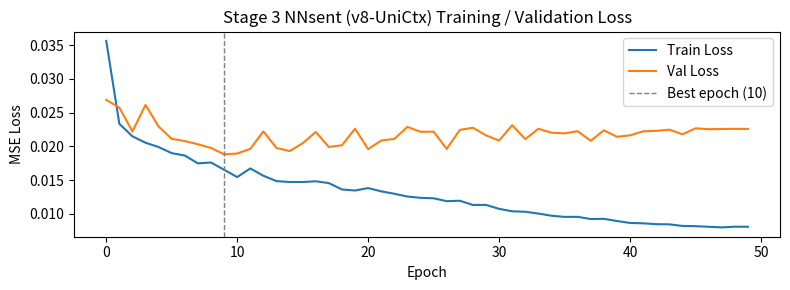

Stage 3 完成（NNword / NNmod 權重全程未被更新）


In [ ]:
model_sent = NNsent(hidden=64).to(device)
for p in model_word.parameters():
    p.requires_grad = False
for p in model_mod.parameters():
    p.requires_grad = False

WEIGHT_DECAY = 1e-4   # L2（Adam weight_decay）
L1_LAMBDA    = 1e-5   # L1（手動加進 loss，只對 Linear 權重矩陣，不含 bias / LayerNorm）


def l1_penalty(model):
    l1 = 0.0
    for p in model.parameters():
        if p.dim() >= 2:
            l1 = l1 + p.abs().sum()
    return l1


opt_sent = optim.Adam(model_sent.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)
sch_sent = optim.lr_scheduler.CosineAnnealingLR(opt_sent, T_max=50)


@torch.no_grad()
def eval_loss_sent(samples):
    """平均 MSE（純預測誤差，不含 L1/L2），拿來監控驗證集。"""
    model_sent.eval()
    if not samples:
        return float('nan')
    total = 0.0
    for s in samples:
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        pv, pa, _ = model_sent(s['ctx'], s['meta'])
        total += (0.5 * ((pv - y_v) ** 2 + (pa - y_a) ** 2).mean()).item()
    return total / len(samples)


print('=== Stage 3：訓練 NNsent（v8-UniCtx）===')
print(f'    L2 (weight_decay)={WEIGHT_DECAY}   L1_LAMBDA={L1_LAMBDA}   SEED={SEED}')
N_EPOCHS_SENT = 50
GRAD_ACCUM_SENT = 16
losses_s, losses_s_val = [], []
best_val, best_epoch, best_state = float('inf'), 0, None

for epoch in range(N_EPOCHS_SENT):
    model_sent.train()
    epoch_loss = 0.0
    idxs = np.random.permutation(len(cvas_train_samples))
    opt_sent.zero_grad()
    for step_i, si in enumerate(idxs, start=1):
        s = cvas_train_samples[si]
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        pv, pa, _ = model_sent(s['ctx'], s['meta'])
        loss_mse = 0.5 * ((pv - y_v) ** 2 + (pa - y_a) ** 2).mean()
        loss = loss_mse + L1_LAMBDA * l1_penalty(model_sent)
        (loss / GRAD_ACCUM_SENT).backward()
        epoch_loss += loss_mse.item()
        if (step_i % GRAD_ACCUM_SENT == 0) or (step_i == len(idxs)):
            torch.nn.utils.clip_grad_norm_(model_sent.parameters(), max_norm=1.0)
            opt_sent.step()
            opt_sent.zero_grad()
    sch_sent.step()
    losses_s.append(epoch_loss / len(idxs))

    val_loss = eval_loss_sent(cvas_val_samples)
    losses_s_val.append(val_loss)
    if val_loss < best_val:
        best_val, best_epoch = val_loss, epoch + 1
        best_state = copy.deepcopy(model_sent.state_dict())

    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_SENT} | Train Loss: {losses_s[-1]:.6f} | Val Loss: {val_loss:.6f}')

if best_state is not None:
    model_sent.load_state_dict(best_state)
    print(f'\n訓練結束，改用驗證損失最低的權重（第 {best_epoch} epoch，Val Loss={best_val:.6f}）')

plt.figure(figsize=(8, 3))
plt.plot(losses_s, label='Train Loss')
plt.plot(losses_s_val, label='Val Loss')
plt.axvline(best_epoch - 1, color='gray', linestyle='--', linewidth=1, label=f'Best epoch ({best_epoch})')
plt.title('Stage 3 NNsent (v8-UniCtx) Training / Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend()
plt.tight_layout(); plt.show()

for p in model_word.parameters():
    p.requires_grad = True
for p in model_mod.parameters():
    p.requires_grad = True
print('Stage 3 完成（NNword / NNmod 權重全程未被更新）')

### 14.5 三階段完整評估（NNword / Pipeline / NNsent）＋ 與 v7-3c 對照

In [ ]:
@torch.no_grad()
def batch_predict_sent(samples):
    model_sent.eval()
    all_pv, all_pa = [], []
    for s in samples:
        pv, pa, _ = model_sent(s['ctx'], s['meta'])
        all_pv.append(pv.item())
        all_pa.append(pa.item())
    return np.array(all_pv, dtype=np.float32), np.array(all_pa, dtype=np.float32)


pv_str, pa_str = batch_predict_sent(cvas_train_samples)
pv_sva, pa_sva = batch_predict_sent(cvas_val_samples)
pv_ste, pa_ste = batch_predict_sent(cvas_test_samples)

print('=' * 75)
print('【Stage 3：CVAS 句子層級評估（v8-UniCtx）】')
print('=' * 75)
print('\n[NNsent] CVAS 訓練集')
compute_metrics(pv_str, cvas_train_val, 'Valence')
compute_metrics(pa_str, cvas_train_aro, 'Arousal')
print('\n[NNsent] CVAS 驗證集（訓練時用來挑最佳 epoch，沒參與梯度更新）')
compute_metrics(pv_sva, cvas_val_val, 'Valence')
compute_metrics(pa_sva, cvas_val_aro, 'Arousal')
print('\n[NNsent] CVAS 測試集')
compute_metrics(pv_ste, cvas_test_val, 'Valence')
compute_metrics(pa_ste, cvas_test_aro, 'Arousal')

rows_cvas = [
    ('NNsent', '訓練', 'Valence', *metrics(pv_str, cvas_train_val)),
    ('NNsent', '訓練', 'Arousal', *metrics(pa_str, cvas_train_aro)),
    ('NNsent', '驗證', 'Valence', *metrics(pv_sva, cvas_val_val)),
    ('NNsent', '驗證', 'Arousal', *metrics(pa_sva, cvas_val_aro)),
    ('NNsent', '測試', 'Valence', *metrics(pv_ste, cvas_test_val)),
    ('NNsent', '測試', 'Arousal', *metrics(pa_ste, cvas_test_aro)),
]
summary_cvas = pd.DataFrame(
    rows_cvas,
    columns=['模型', '資料集', '維度', 'MAE', 'MSE', 'Pearson r', 'Kendall τ', 'Spearman ρ'],
)
summary_all = pd.concat([summary, summary_cvas], ignore_index=True)
print('\n三階段（NNword / Pipeline / NNsent）合併總表：')
print(summary_all.to_string(index=False))

_r_tr_v = metrics(pv_str, cvas_train_val)[2]; _r_va_v = metrics(pv_sva, cvas_val_val)[2]; _r_te_v = metrics(pv_ste, cvas_test_val)[2]
_r_tr_a = metrics(pa_str, cvas_train_aro)[2]; _r_va_a = metrics(pa_sva, cvas_val_aro)[2]; _r_te_a = metrics(pa_ste, cvas_test_aro)[2]
print('\n' + '=' * 75)
print('【過擬合診斷】Pearson r －訓練 / 驗證 / 測試')
print('=' * 75)
print(f'  Valence: {_r_tr_v:.4f} / {_r_va_v:.4f} / {_r_te_v:.4f}   訓練-驗證差距 = {_r_tr_v - _r_va_v:.4f}')
print(f'  Arousal: {_r_tr_a:.4f} / {_r_va_a:.4f} / {_r_te_a:.4f}   訓練-驗證差距 = {_r_tr_a - _r_va_a:.4f}')

# 與 v7-3c（加 L1/L2 後、同一份資料與切分）的測試集結果對照
V73C = {'Valence': 0.7292, 'Arousal': 0.3954}
print('\n【與 v7-3c 對照（測試集 Pearson r）】')
print(f'  Valence: v7-3c={V73C["Valence"]:.4f}  v8-UniCtx={_r_te_v:.4f}  差={_r_te_v - V73C["Valence"]:+.4f}')
print(f'  Arousal: v7-3c={V73C["Arousal"]:.4f}  v8-UniCtx={_r_te_a:.4f}  差={_r_te_a - V73C["Arousal"]:+.4f}')
print(f'  （本次設定 UNICTX_USE_KNN={UNICTX_USE_KNN}, UNICTX_OOV_SPANS={UNICTX_OOV_SPANS}；'
      f'v7 沒有固定隨機種子，單次差異在 ±0.01 內不宜過度解讀）')

【Stage 3：CVAS 句子層級評估（v8-UniCtx）】

[NNsent] CVAS 訓練集
  Valence                        | MAE=0.0814  MSE=0.0107  r=0.8045  τ=0.6185  ρ=0.8025
  Arousal                        | MAE=0.1055  MSE=0.0172  r=0.6045  τ=0.4300  ρ=0.5971

[NNsent] CVAS 驗證集（訓練時用來挑最佳 epoch，沒參與梯度更新）
  Valence                        | MAE=0.0980  MSE=0.0159  r=0.7035  τ=0.5225  ρ=0.6966
  Arousal                        | MAE=0.1152  MSE=0.0217  r=0.4345  τ=0.3149  ρ=0.4515

[NNsent] CVAS 測試集
  Valence                        | MAE=0.0932  MSE=0.0144  r=0.7378  τ=0.5423  ρ=0.7240
  Arousal                        | MAE=0.1124  MSE=0.0200  r=0.4589  τ=0.3280  ρ=0.4726

三階段（NNword / Pipeline / NNsent）合併總表：
      模型 資料集      維度    MAE    MSE  Pearson r  Kendall τ  Spearman ρ
  NNword  訓練 Valence 0.0164 0.0005     0.9954     0.9452      0.9942
  NNword  訓練 Arousal 0.0183 0.0006     0.9921     0.9342      0.9922
  NNword  測試 Valence 0.0735 0.0095     0.8800     0.6658      0.8501
  NNword  測試 Arousal 0.1107 0.0202     0.621

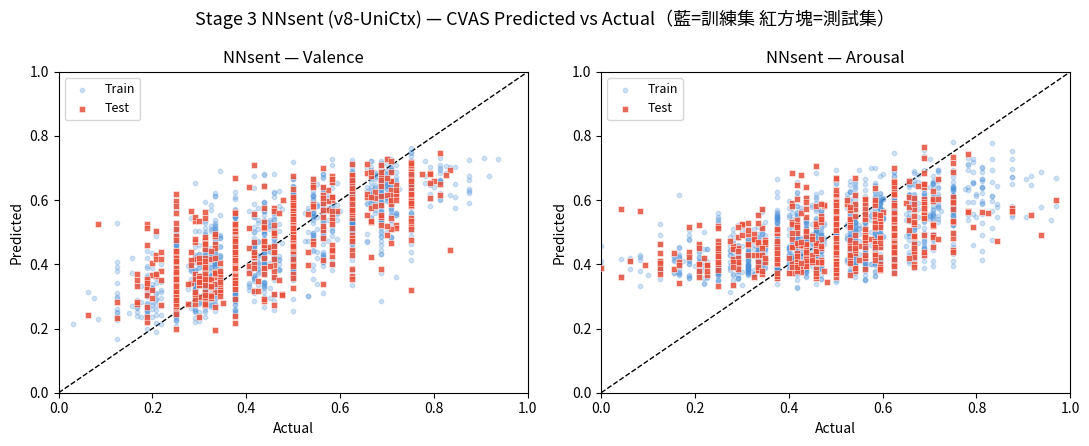

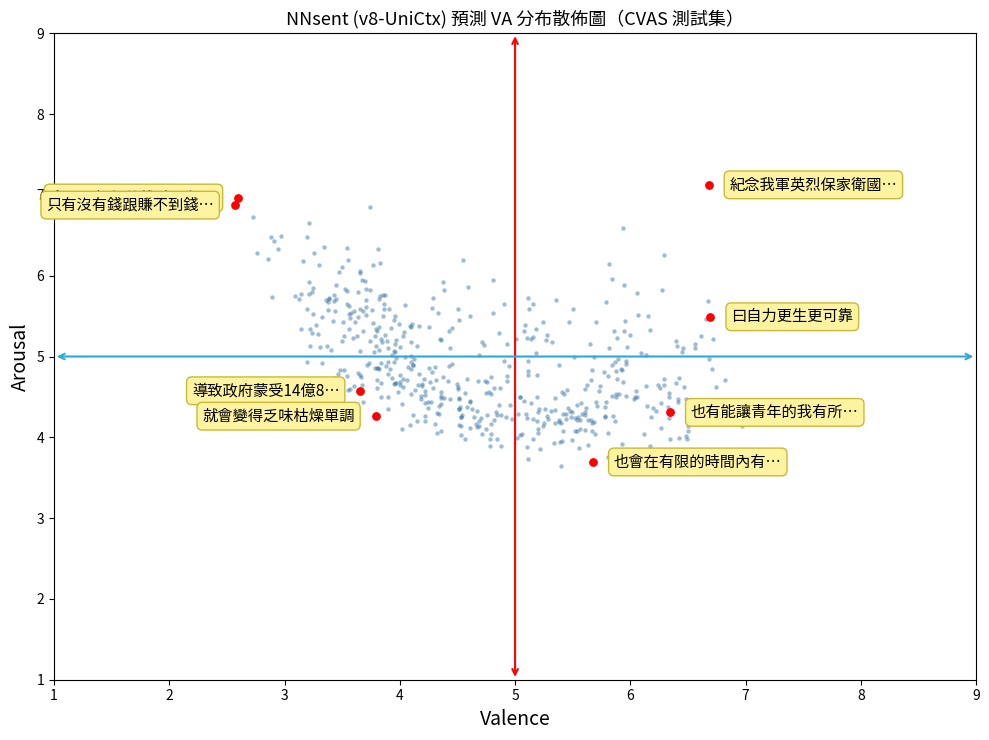

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle('Stage 3 NNsent (v8-UniCtx) — CVAS Predicted vs Actual（藍=訓練集 紅方塊=測試集）', fontsize=13)
configs_sent = [
    (axes[0], pv_str, cvas_train_val, pv_ste, cvas_test_val, 'NNsent — Valence'),
    (axes[1], pa_str, cvas_train_aro, pa_ste, cvas_test_aro, 'NNsent — Arousal'),
]
for ax, ptr, gtr, pte, gte, title in configs_sent:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color='#4A90D9', label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color='#E8503A', marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, zorder=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

plot_va_scatter(pv_ste, pa_ste, [s['sentence'] for s in cvas_test_samples],
                'NNsent (v8-UniCtx) 預測 VA 分布散佈圖（CVAS 測試集）', savepath='nnsent_unictx_va_scatter.png')

### 14.6 哪些詞有幫助、哪些沒作用：Leave-One-Out 消融 + 每步貢獻度排行榜

作法同 v7：對每個 span 輪流整個拿掉（遞迴鏈，後面步驟的狀態會跟著變，所以不能只是遮罩），重跑一次 NNsent，
比較整句 VA 的變化 `ΔV / ΔA`。因為 adapter 對每個 span 獨立計算，拿掉某個 span 只要把 `ctx` / `meta` 那一列刪掉即可，
不需要重跑 BERT。

**v8 新增（教授第 2 點「這個字有沒有用」的直接證據）：** 依 `seen_state`（seen / unseen_lex / oov）
分組比較平均 `impact`——如果「沒看過的字」（unseen_lex、oov）的 impact 跟「看過的字」差不多，
代表統一路徑 + 鄰近度確實讓沒看過的字也能對整句 VA 有貢獻；如果 oov 的 impact 明顯偏低，
則代表鄰近度收進來的詞多半是雜訊，可以調高 `OOV_SIM_PCT` 門檻。

In [ ]:
@torch.no_grad()
def _nnsent_forward(ctx, meta):
    v, a, steps = model_sent(ctx, meta)
    return v.item(), a.item(), steps


@torch.no_grad()
def compute_span_importance(sample):
    """
    對一個樣本計算每個 span 的：
      contrib_v/contrib_a — NNsent 該步驟對句子狀態的貢獻強度（0.5=沒影響）
      delta_v/delta_a     — Leave-One-Out：把這個 span 拿掉後，整句最終 VA 的變化量
      impact              — sqrt(delta_v^2 + delta_a^2)
    """
    model_sent.eval()
    ctx, meta, infos = sample['ctx'], sample['meta'], sample['span_infos']
    n = len(infos)
    full_v, full_a, steps = _nnsent_forward(ctx, meta)

    results = []
    for i in range(n):
        if n == 1:
            loo_v, loo_a = 0.5, 0.5          # 只有一個 span，拿掉後視為中性
        else:
            keep = [j for j in range(n) if j != i]
            loo_v, loo_a, _ = _nnsent_forward(ctx[keep], meta[keep])
        dv, da = full_v - loo_v, full_a - loo_a
        results.append({
            'span_text': infos[i]['span_text'], 'core_word': infos[i]['core_word'],
            'modifier': infos[i]['modifier'], 'hit': infos[i]['hit'],
            'kind': infos[i]['kind'], 'seen_state': infos[i]['seen_state'], 'conf': infos[i]['conf'],
            'contrib_v': float(steps[i][0]), 'contrib_a': float(steps[i][1]),
            'delta_v': float(dv), 'delta_a': float(da),
            'impact': float(np.sqrt(dv ** 2 + da ** 2)),
        })
    return full_v, full_a, results


print('compute_span_importance 定義完成')

compute_span_importance 定義完成


#### 全測試集彙整：資料驅動的「有幫助 / 普通 / 沒作用」門檻

In [ ]:
print('對整個 CVAS 測試集跑 Leave-One-Out 消融（只重跑 NNsent，很快）...')
all_span_rows = []
for s in cvas_test_samples:
    _, _, span_results = compute_span_importance(s)
    for r in span_results:
        r['sentence'] = s['sentence']
        all_span_rows.append(r)

span_df = pd.DataFrame(all_span_rows)
span_df['contrib'] = (span_df['contrib_v'] + span_df['contrib_a']) / 2
print(f'共分析 {len(span_df)} 個 span（來自 {len(cvas_test_samples)} 個測試句子）')

q_low, q_high = span_df['impact'].quantile([0.33, 0.67])


def label_usefulness(impact):
    if impact >= q_high:
        return '有幫助'
    if impact <= q_low:
        return '沒作用'
    return '普通'


span_df['usefulness'] = span_df['impact'].apply(label_usefulness)
print(f'\nimpact 三分位門檻: 33%={q_low:.4f}  67%={q_high:.4f}')
print(span_df['usefulness'].value_counts())

print('\n=== 依「看過 / 沒看過」分組（教授第 2 點）：平均對整句 VA 的貢獻 ===')
seen_rank = (span_df.groupby('seen_state')
             .agg(n=('impact', 'size'), mean_impact=('impact', 'mean'),
                  mean_contrib=('contrib', 'mean'), mean_conf=('conf', 'mean'),
                  frac_useful=('usefulness', lambda x: (x == '有幫助').mean())))
print(seen_rank.to_string())
print('  seen=NNword 訓練看過；unseen_lex=在 CVAW 但屬於 cvaw_test；oov=完全不在 CVAW（由鄰近度收進來）')

對整個 CVAS 測試集跑 Leave-One-Out 消融（只重跑 NNsent，很快）...
共分析 1227 個 span（來自 517 個測試句子）

impact 三分位門檻: 33%=0.0275  67%=0.0659
usefulness
普通     417
沒作用    405
有幫助    405
Name: count, dtype: int64

=== 依「看過 / 沒看過」分組（教授第 2 點）：平均對整句 VA 的貢獻 ===
              n  mean_impact  mean_contrib  mean_conf  frac_useful
seen_state                                                        
fallback      1     0.105007      0.460337   0.000000     1.000000
oov         543     0.034050      0.485706   0.572807     0.130755
seen        563     0.071866      0.498116   0.557164     0.493783
unseen_lex  120     0.072822      0.503006   0.581781     0.458333
  seen=NNword 訓練看過；unseen_lex=在 CVAW 但屬於 cvaw_test；oov=完全不在 CVAW（由鄰近度收進來）


#### 依「情感詞（核心詞）」與「修飾詞」分組的重要性排行榜

In [ ]:
print('=== 依「情感詞（核心詞）」分組：平均對整句 VA 的貢獻 ===')
core_rank = (
    span_df[span_df['core_word'].notna()]
    .groupby('core_word')
    .agg(n=('impact', 'size'), mean_impact=('impact', 'mean'), mean_contrib=('contrib', 'mean'),
         mean_dV=('delta_v', 'mean'), mean_dA=('delta_a', 'mean'), mean_conf=('conf', 'mean'),
         seen_state=('seen_state', 'first'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print('\n【最有幫助的情感詞（平均 impact 最高，前 20）】')
print(core_rank.head(20).to_string())
print('\n【幾乎沒作用的情感詞（平均 impact 最低，前 20）】')
print(core_rank.tail(20).sort_values('mean_impact').to_string())

print('\n=== 依「修飾詞」分組：平均對整句 VA 的貢獻 ===')
mod_rank = (
    span_df[span_df['modifier'].notna()]
    .groupby('modifier')
    .agg(n=('impact', 'size'), mean_impact=('impact', 'mean'), mean_contrib=('contrib', 'mean'),
         mean_dV=('delta_v', 'mean'), mean_dA=('delta_a', 'mean'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print(mod_rank.to_string())

core_rank.to_csv('cvas_unictx_core_word_importance.csv', encoding='utf-8-sig')
mod_rank.to_csv('cvas_unictx_modifier_importance.csv', encoding='utf-8-sig')
span_df.to_csv('cvas_unictx_span_importance_raw.csv', index=False, encoding='utf-8-sig')
print('\n已輸出：cvas_unictx_core_word_importance.csv / cvas_unictx_modifier_importance.csv / cvas_unictx_span_importance_raw.csv')

=== 依「情感詞（核心詞）」分組：平均對整句 VA 的貢獻 ===

【最有幫助的情感詞（平均 impact 最高，前 20）】
           n  mean_impact  mean_contrib   mean_dV   mean_dA  mean_conf  seen_state
core_word                                                                         
造謠         2     0.128612      0.478186 -0.113421  0.055099   0.457945        seen
責任         2     0.111305      0.515763 -0.091925  0.062651   0.574616         oov
殘酷         2     0.088199      0.518624 -0.066438  0.057652   0.908302        seen
繁榮         2     0.087771      0.643224  0.073219  0.048401   0.525567  unseen_lex
壓榨         2     0.080704      0.530997 -0.044203  0.067246   0.497945         oov
惡行         2     0.079361      0.505384 -0.052201  0.051139   0.874047        seen
不可         2     0.077565      0.453308 -0.055022 -0.010847   0.577759        seen
遵守         2     0.073690      0.472798 -0.003945 -0.016339   0.545344        seen
真是         2     0.071982      0.578785 -0.006327  0.056478   0.624171         oov
厭煩         2     0.07

#### 單句 Demo：逐 span 列出 contribution + LOO 貢獻 + 有幫助/沒作用 標籤（多了 kind 與 conf）

In [ ]:
@torch.no_grad()
def predict_sentence_with_importance(sentence, verbose=True):
    model_word.eval(); model_mod.eval(); model_sent.eval()
    sample = build_unified_sample(sentence)
    full_v, full_a, span_results = compute_span_importance(sample)

    fv9 = round(full_v * 8 + 1, 3)
    fa9 = round(full_a * 8 + 1, 3)
    pol = '正向' if full_v > 0.625 else ('負向' if full_v < 0.375 else '中性')
    act = '高喚起' if full_a > 0.625 else ('低喚起' if full_a < 0.375 else '中喚起')

    if verbose:
        print(f'\n句子：「{sentence}」')
        print(f'整句 VA（1-9）→ Valence={fv9}  Arousal={fa9}  [{pol}/{act}]\n')
        print(f'{"span":14s} {"kind":8s} {"狀態":10s} {"conf":>6} {"contrib":>8} {"DV":>8} {"DA":>8} {"impact":>8}  判斷')
        print('-' * 88)
        for r in sorted(span_results, key=lambda x: -x['impact']):
            tag = label_usefulness(r['impact'])
            contrib_disp = (r['contrib_v'] + r['contrib_a']) / 2
            print(f'{r["span_text"]:14s} {r["kind"]:8s} {r["seen_state"]:10s} {r["conf"]:6.3f} {contrib_disp:8.3f} '
                  f'{r["delta_v"]:8.4f} {r["delta_a"]:8.4f} {r["impact"]:8.4f}  {tag}')
    return fv9, fa9, span_results


print('\n=== 句子推論 + 逐詞重要性 Demo ===')
for s in [
    '這次旅行真的非常開心，風景美極了！',
    '主治醫師強調血液透析，家屬却遲遲無法達到共識。',
    '視病如親，讓我十分的動容。',
    '雖然考試沒過，但心情還算平靜。',
    '非常憤怒，完全無法接受這種行為！',
]:
    predict_sentence_with_importance(s)


=== 句子推論 + 逐詞重要性 Demo ===

句子：「這次旅行真的非常開心，風景美極了！」
整句 VA（1-9）→ Valence=6.818  Arousal=6.656  [正向/高喚起]

span           kind     狀態           conf  contrib       DV       DA   impact  判斷
----------------------------------------------------------------------------------------
非常開心           lex      seen        0.595    0.673   0.0583   0.0817   0.1003  有幫助
極了             oov      oov         0.497    0.545  -0.0060   0.0554   0.0558  普通
真的             oov      oov         0.615    0.624   0.0234   0.0473   0.0528  普通
旅行             oov      oov         0.500    0.552   0.0234  -0.0012   0.0235  沒作用

句子：「主治醫師強調血液透析，家屬却遲遲無法達到共識。」
整句 VA（1-9）→ Valence=4.175  Arousal=4.472  [中性/中喚起]

span           kind     狀態           conf  contrib       DV       DA   impact  判斷
----------------------------------------------------------------------------------------
達到             lex      seen        0.535    0.537   0.0697  -0.0165   0.0716  有幫助
無法             lex      seen        0.482    0.444  -0.0285 